In [1]:
#Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from lmfit.models import GaussianModel, VoigtModel, ConstantModel
from scipy.special import wofz
from pathlib import Path
from scipy.ndimage import median_filter
from scipy.signal import find_peaks

<h3 style="color: #e19edc;"> Lectura de espectros del 2018 y 2019</h3>
<h5 style="color: #e19edc;"> Los espectros del 2019 fueron tomados en las Islas Canarias</h5>

In [2]:
#Rutas Julio, Agosto y Septiembre

ruta_24_julio = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-07-24.xlsx"
ruta_27_julio = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-07-27.xlsx"
ruta_03_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-08-03.xlsx"
ruta_07_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-08-07.xlsx"
ruta_11_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-08-11.xlsx"
ruta_16_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-08-16.xlsx"
ruta_23_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-08-23.xlsx"
ruta_29_agosto = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-08-29.xlsx"
ruta_11_septiembre = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2018-09-11.xlsx"
ruta_05_agosto_19 = r"C:\Users\Jessi Dani\OneDrive - Universidad de los andes\TESIS\Tesis\Datos ESPARTACO\Espectros de Antares\2018 y 2019\2019-08-05.xlsx"

In [3]:
#Datos de Julio, Agosto y Septiembre

antares_24_julio = pd.read_excel(ruta_24_julio, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_27_julio = pd.read_excel(ruta_27_julio, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_03_agosto = pd.read_excel(ruta_03_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_07_agosto = pd.read_excel(ruta_07_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_11_agosto = pd.read_excel(ruta_11_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_16_agosto = pd.read_excel(ruta_16_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_23_agosto = pd.read_excel(ruta_23_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_29_agosto = pd.read_excel(ruta_29_agosto, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_11_septiembre = pd.read_excel(ruta_11_septiembre, sheet_name = "Sheet1", usecols = [1,2],header = None, names = ["Longitud onda", "Flujo"])
antares_05_agosto_19 = pd.read_excel(ruta_05_agosto_19, sheet_name = "Sheet1", usecols = [0,1],header = None, names = ["Longitud onda", "Flujo"])

In [4]:
espectros = {
    "antares_24_julio": antares_24_julio,
    "antares_27_julio": antares_27_julio,
    "antares_03_agosto": antares_03_agosto,
    "antares_07_agosto": antares_07_agosto,
    "antares_11_agosto": antares_11_agosto,
    "antares_16_agosto": antares_16_agosto,
    "antares_23_agosto": antares_23_agosto,
    "antares_29_agosto": antares_29_agosto,
    "antares_11_septiembre": antares_11_septiembre,
    "antares_05_agosto_19": antares_05_agosto_19
}

<h4 style="color: #e19edc;"> Parámetros de la normalización con el método Sigma - Clipping</h4>

In [5]:
guardar_graficos = True   
carpeta_graficos = "./Graficas 2018 y 2019/Espectros_normalizados"  
 
col_longitud_onda = "Longitud onda"
col_flujo = "Flujo"
 
grado_polinomio= 2     
N_iteraciones = 10
sigma_corte = 2.0

<h5 style="color: #e19edc;"> Modelo</h5>

In [6]:
def ajustar_continuo(longitud_onda, flujo, grado, n_iter, sigma):

    longitud_onda = np.asarray(longitud_onda, dtype=float)
    flujo = np.asarray(flujo, dtype=float)
 
    mascara = np.ones_like(flujo, dtype=bool)
 
    for _ in range(n_iter):
        coef = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
        continuo_iter = np.polyval(coef, longitud_onda)
 
        residuo = flujo - continuo_iter
        
        mediana = np.median(residuo[mascara])
        mad = np.median(np.abs(residuo[mascara] - mediana))
        mad_std = mad * 1.4826

        umbral_superior = mediana + sigma * mad_std
        umbral_inferior = mediana - sigma * mad_std
        nueva_mascara = (residuo > umbral_inferior) & (residuo < umbral_superior)
 
        if nueva_mascara.sum() < grado + 2:
            break

        if np.array_equal(nueva_mascara, mascara):
            break
 
        mascara = nueva_mascara
 
    coef_final = np.polyfit(longitud_onda[mascara], flujo[mascara], deg=grado)
    continuo = np.polyval(coef_final, longitud_onda)
 
    return continuo, mascara


<h5 style="color: #e19edc;"> Verificación del modelo con gráficos</h5>


Procesando: antares_24_julio
  Puntos totales: 203
  Puntos excluidos: 51
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_24_julio_control.png


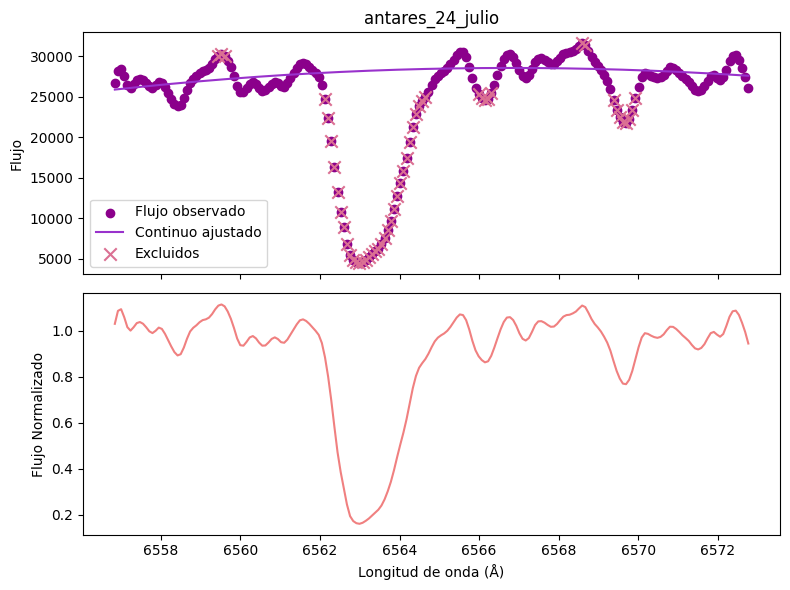


Procesando: antares_27_julio
  Puntos totales: 158
  Puntos excluidos: 68
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_27_julio_control.png


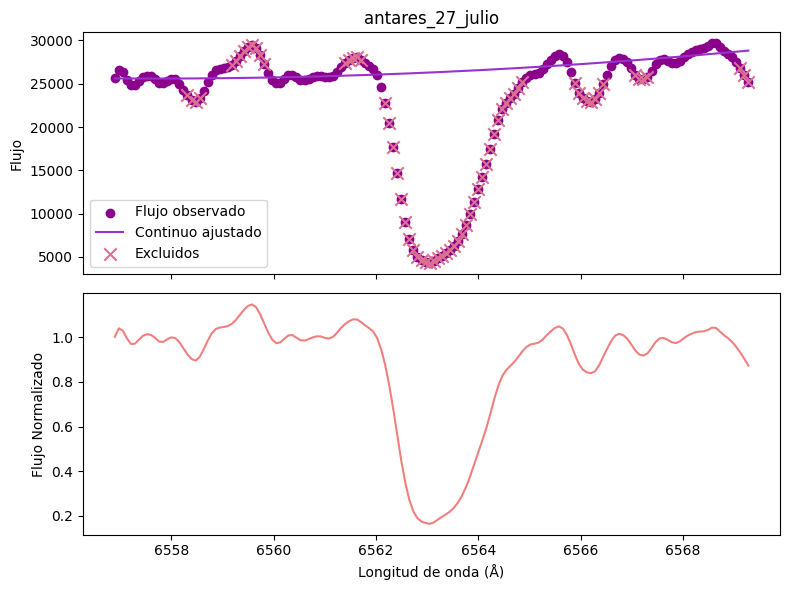


Procesando: antares_03_agosto
  Puntos totales: 161
  Puntos excluidos: 44
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_03_agosto_control.png


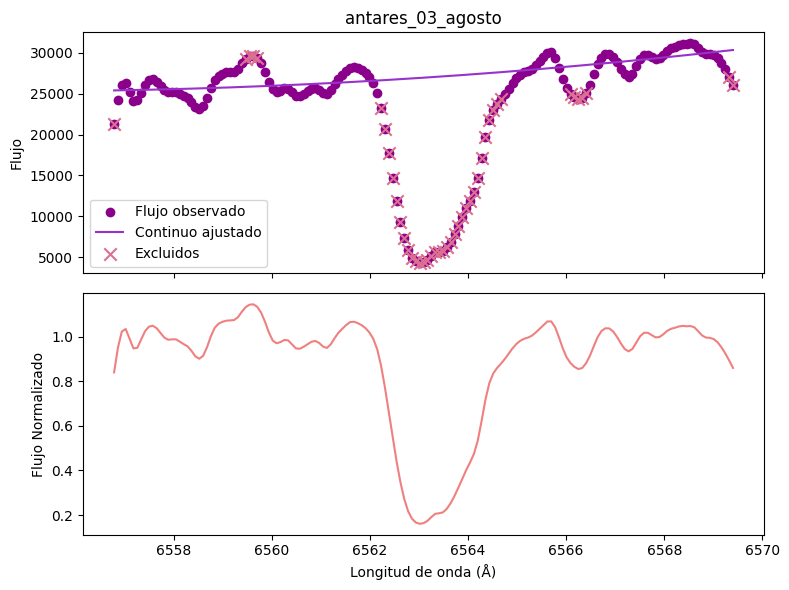


Procesando: antares_07_agosto
  Puntos totales: 162
  Puntos excluidos: 54
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_07_agosto_control.png


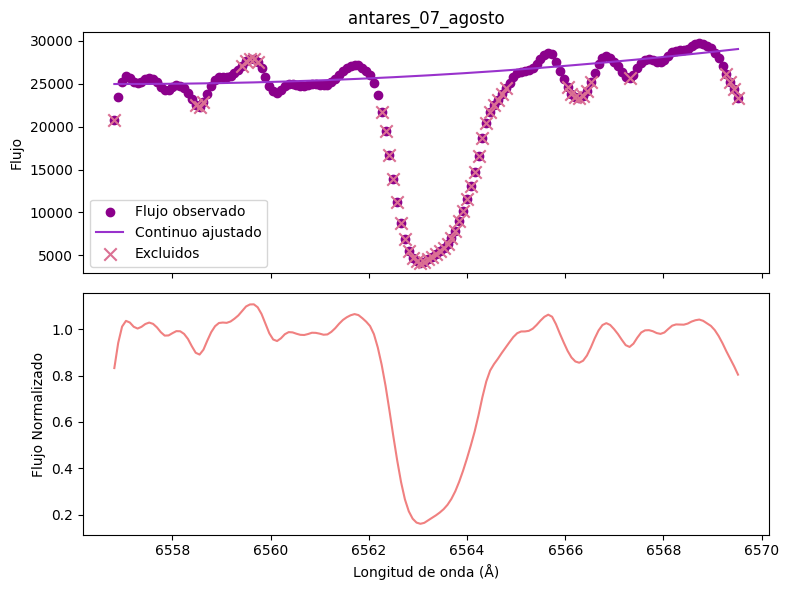


Procesando: antares_11_agosto
  Puntos totales: 163
  Puntos excluidos: 62
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_11_agosto_control.png


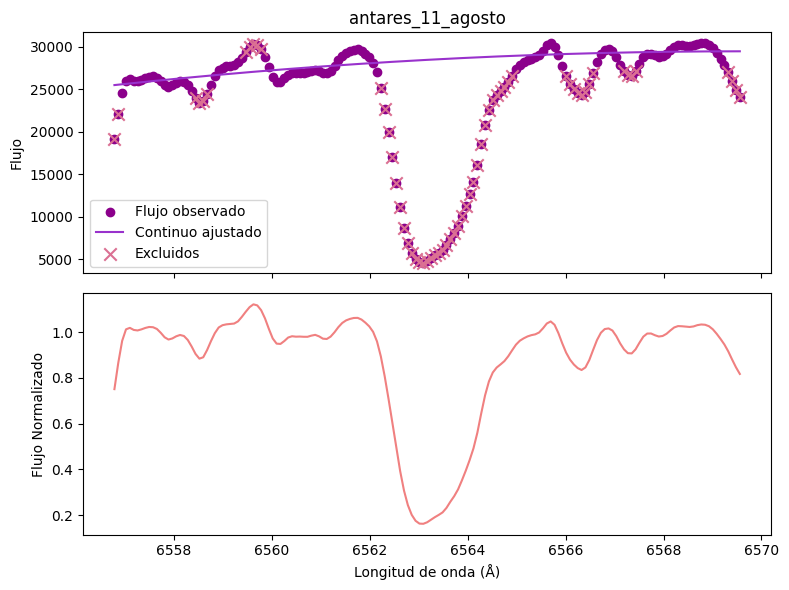


Procesando: antares_16_agosto
  Puntos totales: 163
  Puntos excluidos: 61
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_16_agosto_control.png


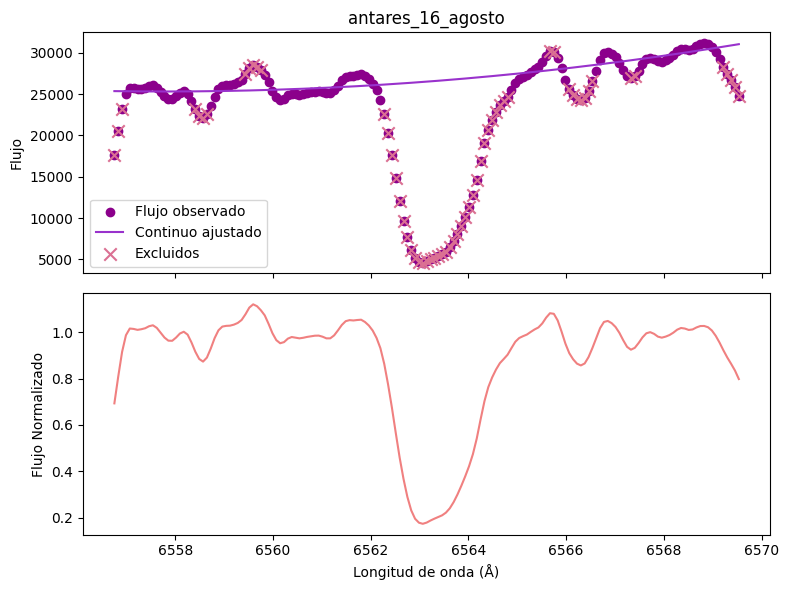


Procesando: antares_23_agosto
  Puntos totales: 162
  Puntos excluidos: 52
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_23_agosto_control.png


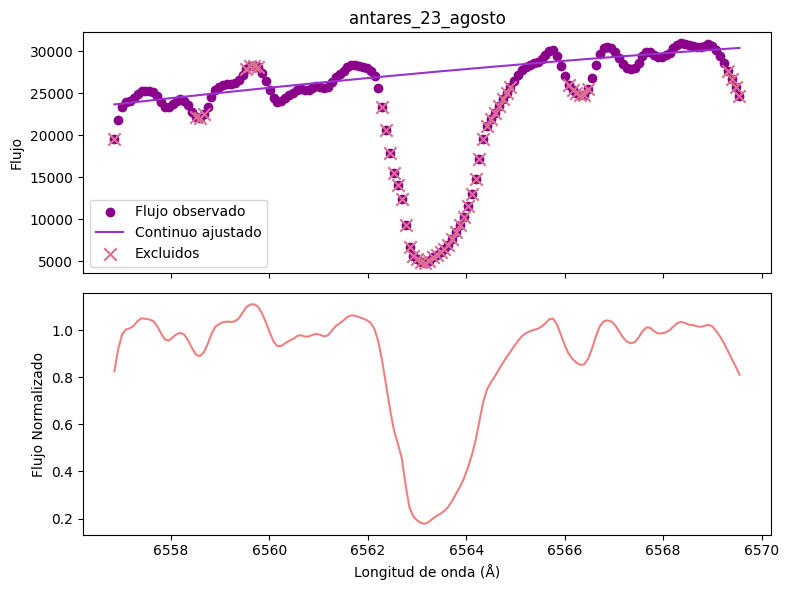


Procesando: antares_29_agosto
  Puntos totales: 206
  Puntos excluidos: 83
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_29_agosto_control.png


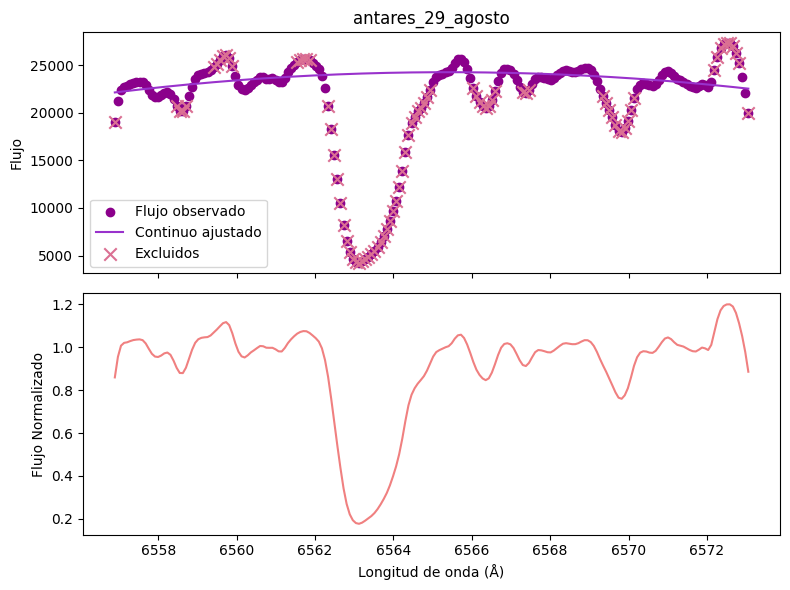


Procesando: antares_11_septiembre
  Puntos totales: 208
  Puntos excluidos: 64
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_11_septiembre_control.png


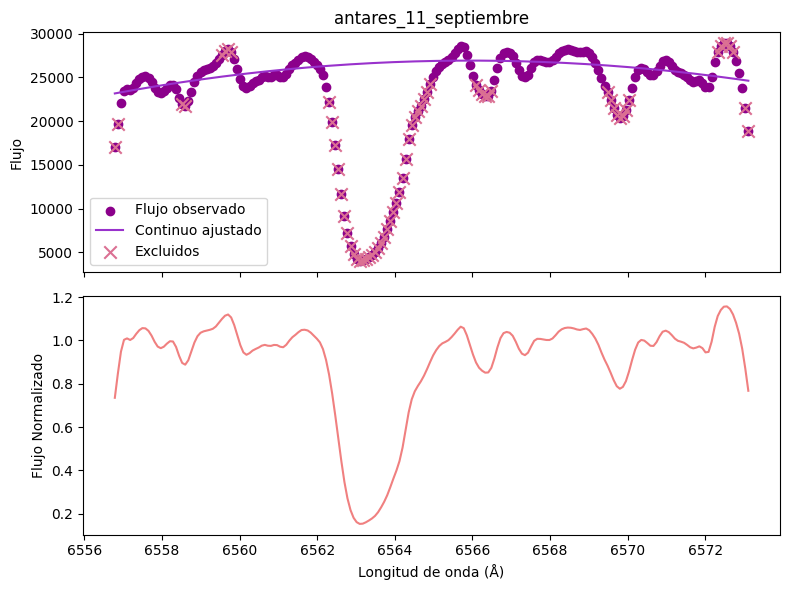


Procesando: antares_05_agosto_19
  Puntos totales: 290
  Puntos excluidos: 147
  -> Gráfico guardado: Graficas 2018 y 2019\Espectros_normalizados\antares_05_agosto_19_control.png


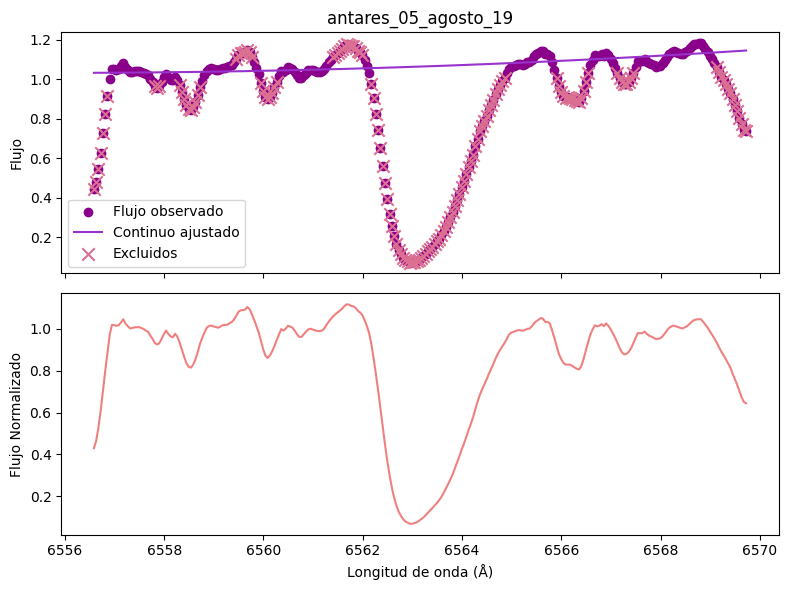


Proceso completo.


In [7]:
if guardar_graficos:
    Path(carpeta_graficos).mkdir(exist_ok=True)
 
for nombre, df in espectros.items():
    print(f"\nProcesando: {nombre}")
 
    longitud_onda = df[col_longitud_onda].values
    flujo = df[col_flujo].values
 
    continuo, mascara_continuo = ajustar_continuo(longitud_onda, flujo, grado_polinomio, N_iteraciones, sigma_corte)

    df["Continuo ajustado"] = continuo
    df["Flujo Normalizado"] = flujo / continuo
    df["Usado en ajuste"] = mascara_continuo

    print(f"  Puntos totales: {len(mascara_continuo)}")
    print(f"  Puntos excluidos: {(~mascara_continuo).sum()}")

    mascara_bool = np.asarray(mascara_continuo, dtype=bool)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
 
    ax1.scatter(longitud_onda, flujo, color = "darkmagenta", label="Flujo observado")
    ax1.plot(longitud_onda, continuo, color ="darkorchid", label="Continuo ajustado")
    ax1.scatter(longitud_onda[~mascara_bool], flujo[~mascara_bool], color = "palevioletred",marker = "x", label="Excluidos", s = 80)
    ax1.set_ylabel("Flujo")
    ax1.legend()
    ax1.set_title(nombre)
 
    ax2.plot(longitud_onda, df["Flujo Normalizado"], color ="lightcoral")
    ax2.set_ylabel("Flujo Normalizado")
    ax2.set_xlabel("Longitud de onda (Å)")
 
    plt.tight_layout()
 
    if guardar_graficos:
        fig_path = Path(carpeta_graficos) / f"{nombre}_control.png"
        plt.savefig(fig_path, dpi=120)
        print(f"  -> Gráfico guardado: {fig_path}")
 
    plt.show()
    plt.close(fig)
 
print("\nProceso completo.")

In [8]:
metadatos = {
    "antares_24_julio": {
        "fecha": "Julio 24-2018",
        "datos": antares_24_julio,
        "ventana_vecinos": 4,
        "centro_aprox": 6562.994,
        "Velocidad Hα": 19.4, #km/s
        "Incertidumbre v Hα": 0.7,
        "Velocidad Sector naranja": 19.76, #km/s
        "Incertidumbre v Sector naranja": 0.05,
        "Velocidad Telurica": -22.83, #km/s
    },
    "antares_27_julio": {
        "fecha": "Julio 27-2018",
        "datos": antares_27_julio,
        "ventana_vecinos": 4,
        "centro_aprox": 6563.045,
        "Velocidad Hα": 20.2, #km/s
        "Incertidumbre v Hα": 0.8,
        "Velocidad Telurica":-23.87, #km/s
    },
    "antares_03_agosto": {
        "fecha": "Agosto 03-2018",
        "datos": antares_03_agosto,
        "ventana_vecinos": 3,
        "centro_aprox": 6563.015,
        "Velocidad Hα": 23, #km/s
        "Incertidumbre v Hα": 0.9,
        "Velocidad Sector naranja": 23.5, #km/s
        "Incertidumbre v Sector naranja": 0.03,
        "Velocidad Telurica": -26.00, #km/s
    },
    "antares_07_agosto": {
        "fecha": "Agosto 07-2018",
        "datos": antares_07_agosto,
        "ventana_vecinos": 3,
        "centro_aprox": 6563.05116,
        "Velocidad Hα": 23.9, #km/s
        "Incertidumbre v Hα": 0.5,
        "Velocidad Sector naranja": 24.1, #km/s
        "Incertidumbre v Sector naranja": 0.04,
        "Velocidad Telurica": -26.59, #km/s
    },
    "antares_11_agosto": {
        "fecha": "Agosto 11-2018",
        "datos": antares_11_agosto,
        "ventana_vecinos": 3,
        "centro_aprox": 6563.091,
        "Velocidad Hα": 24.9, #km/s
        "Incertidumbre v Hα": 0.7,
        "Velocidad Telurica": -27.58, #km/s
    },
    "antares_16_agosto": {
        "fecha": "Agosto 16-2018",
        "datos": antares_16_agosto,
        "ventana_vecinos": 3,
        "centro_aprox": 6563.067,
        "Velocidad Hα": 25.1, #km/s
        "Incertidumbre v Hα": 0.4,
        "Velocidad Sector naranja": 25.8, #km/s
        "Incertidumbre v Sector naranja": 0.06,
        "Velocidad Telurica": -28.19, #km/s
    },
    "antares_23_agosto": {
        "fecha": "Agosto 23-2018",
        "datos": antares_23_agosto,
        "ventana_vecinos": 3,
        "centro_aprox": 6563.164,
        "Velocidad Hα": 26, #km/s
        "Incertidumbre v Hα": 0.5,
        "Velocidad Sector naranja": 26.18, #km/s
        "Incertidumbre v Sector naranja": 0.11,
        "Velocidad Telurica": -29.21, #km/s
    },
    "antares_29_agosto": {
        "fecha": "Agosto 29-2018",
        "datos": antares_29_agosto,
        "ventana_vecinos": 3,
        "centro_aprox": 6563.131,
        "Velocidad Hα": 26.3, #km/s
        "Incertidumbre v Hα": 0.4,
        "Velocidad Sector naranja": 27.09, #km/s
        "Incertidumbre v Sector naranja": 0.15,
        "Velocidad Telurica": -29.47, #km/s
    },
    "antares_11_septiembre": {
        "fecha": "Septiembre 11-2018",
        "datos": antares_11_septiembre,
        "ventana_vecinos": 3,
        "centro_aprox": 6563.095,
        "Velocidad Hα": 26, #km/s
        "Incertidumbre v Hα": 0.5,
        "Velocidad Sector naranja": 26.75, #km/s
        "Incertidumbre v Sector naranja": 0.09,
        "Velocidad Telurica": -29.36, #km/s
    },
    "antares_05_agosto_19": {
        "fecha": "Agosto 05-2019",
        "datos": antares_05_agosto_19,
        "ventana_vecinos": 3,
        "centro_aprox": 6562.948,
        "Velocidad Hα": 23, #km/s
        "Incertidumbre v Hα": 0.5,
        "Velocidad Telurica": -26.24, #km/s
    },
}

<h3 style="color: #e19edc;"> Obtención del perfil de absorción y emisión de la línea H<sub>&alpha;</sub></h3>

<h4 style="color: #e19edc;"> Teniendo en cuenta las posibles mezclas con las líneas de absorción</h4>

<h5 style="color: #e19edc;"> Funciones complementarias</h5>

In [9]:
c_kms_s = 299792.458

def efecto_doppler(longitud_lab, velocidad_kms):
    return longitud_lab * (1 + velocidad_kms / c_kms_s)

def profundidad_interpolada(teff, t_ref=(3500, 4250), prof_ref=(0.55, 0.63)):
    return float(np.interp(teff, t_ref, prof_ref))

def pico_unitario_voigt(sigma, gamma):
    z = 1j * gamma / (sigma * np.sqrt(2))
    return wofz(z).real / (sigma * np.sqrt(2 * np.pi))

In [10]:
def estimar_continuo_por_planitud(longitud_onda, flujo, rango_flujo,max_variacion=0.015, ventana_vecinos=2,
                                    grado_ajuste=1, min_puntos=5):

    serie_flujo = pd.Series(flujo)

    ventana_total = 2 * ventana_vecinos + 1
    variacion_local = serie_flujo.rolling(window=ventana_total, center=True).std()

    mascara_rango = (flujo >= rango_flujo[0]) & (flujo <= rango_flujo[1])
    mascara_plano = (variacion_local < max_variacion).to_numpy()

    mascara = mascara_rango & mascara_plano

    x_sel = longitud_onda[mascara]
    y_sel = flujo[mascara]

    if x_sel.size < min_puntos:
        raise ValueError(
            f"Solo se encontraron {x_sel.size} puntos de continuo (mínimo {min_puntos}). "
            f"Ajustá 'rango_flujo' o 'max_variacion'. Rango de flujo real en este espectro: "
            f"[{flujo.min():.3f}, {flujo.max():.3f}]"
        )

    orden = np.argsort(x_sel)
    x_sel, y_sel = x_sel[orden], y_sel[orden]

    coef = np.polyfit(x_sel, y_sel, deg=grado_ajuste)
    continuo_func = np.poly1d(coef)

    return continuo_func, x_sel, y_sel

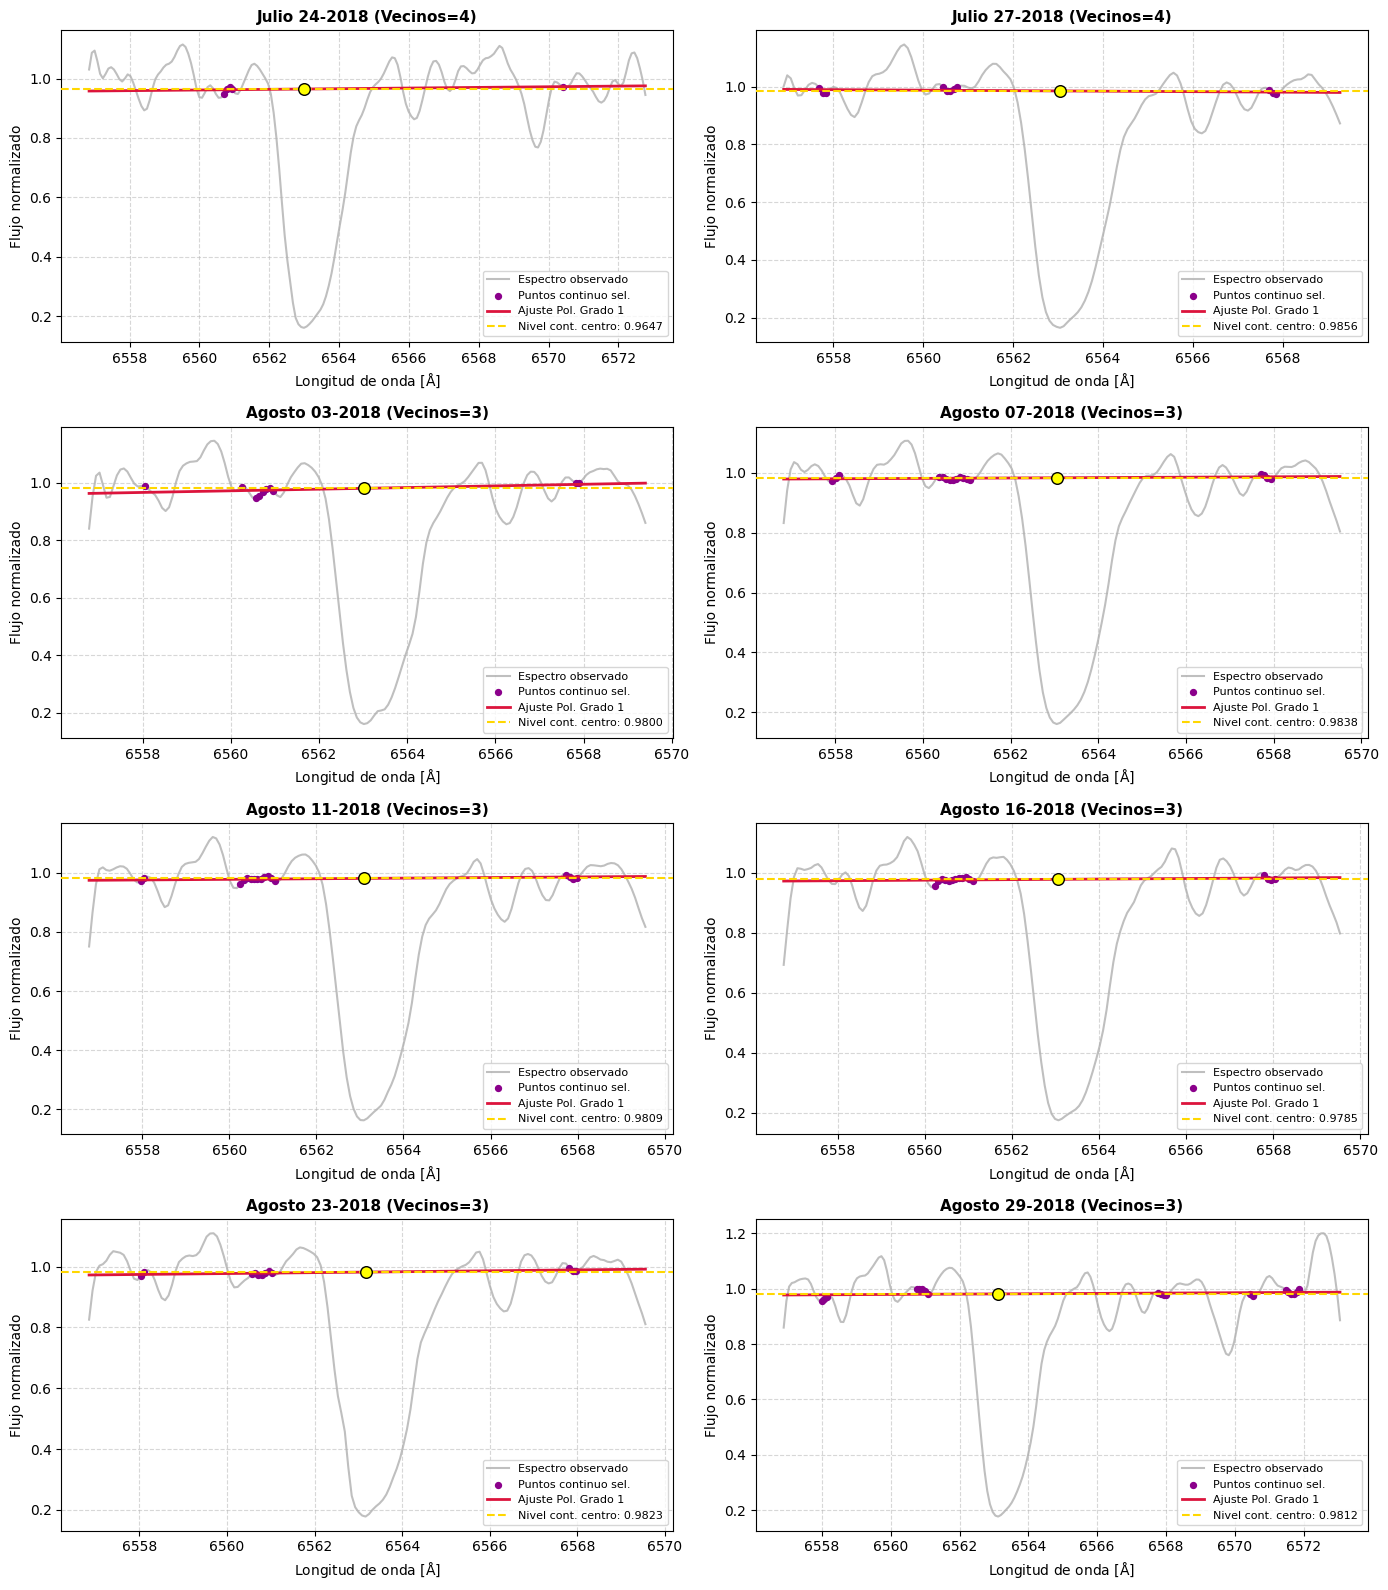

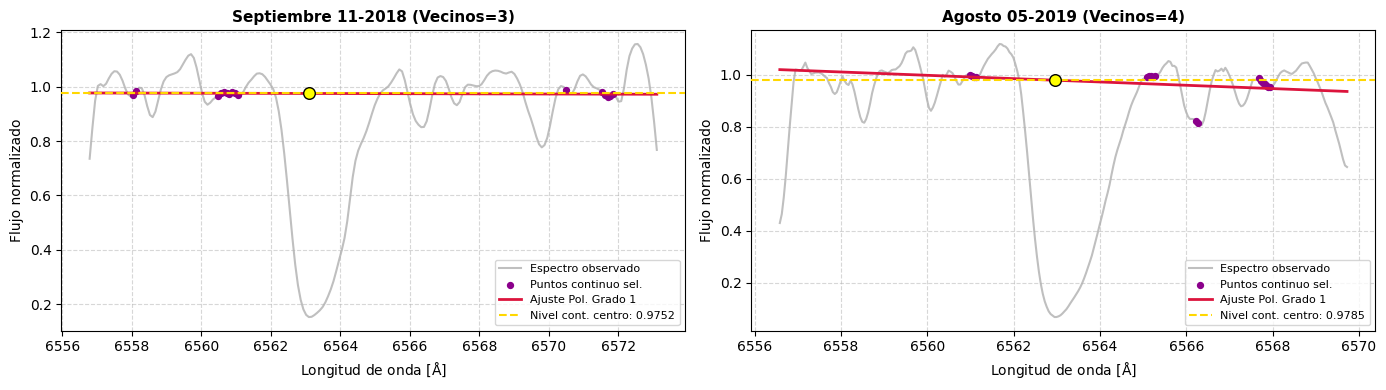

,Espectro / Fecha,Vecinos (G1),Continuo Centro (G1),Residuo std (G1)
0,Julio 24-2018,4,0.9647,0.00719
1,Julio 27-2018,4,0.9856,0.00767
2,Agosto 03-2018,3,0.9800,0.01376
3,Agosto 07-2018,3,0.9838,0.00570
4,Agosto 11-2018,3,0.9809,0.00620
5,Agosto 16-2018,3,0.9785,0.00686
6,Agosto 23-2018,3,0.9823,0.00466
7,Agosto 29-2018,3,0.9812,0.01119
8,Septiembre 11-2018,3,0.9752,0.00631
9,Agosto 05-2019,4,0.9785,0.05023


In [11]:
# Configuración manual de vecinos por prueba específica

vecinos_manuales = {
    "Julio 24-2018": {"v_g1": 4},
    "Julio 27-2018": {"v_g1": 4},
    "Agosto 03-2018": {"v_g1": 3},
    "Agosto 07-2018": {"v_g1": 3},
    "Agosto 11-2018": {"v_g1": 3},
    "Agosto 16-2018": {"v_g1": 3},
    "Agosto 23-2018": {"v_g1": 3},
    "Agosto 29-2018": {"v_g1": 3},
    "Septiembre 11-2018": {"v_g1": 3},
    "Agosto 05-2019": {"v_g1": 4},
}

filas_comparativa = []

n_columnas = 2
max_filas = 4
tam_bloque = n_columnas * max_filas

lista_metadatos = list(metadatos.values())

n_bloques = int(np.ceil(len(lista_metadatos) / tam_bloque))

for bloque_idx in range(n_bloques):

    bloque = lista_metadatos[bloque_idx * tam_bloque: (bloque_idx + 1) * tam_bloque]
    n_graficas = len(bloque)
    n_filas_bloque = int(np.ceil(n_graficas / n_columnas))

    fig, axes = plt.subplots(
        n_filas_bloque,
        n_columnas,
        figsize=(14, 4 * n_filas_bloque)
    )

    axes = np.array(axes).flatten()

    for i, archivo in enumerate(bloque):

        fecha = archivo["fecha"]
        df = archivo["datos"]
        centro_aprox = archivo["centro_aprox"]

        longitud_onda = df["Longitud onda"].values
        flujo = df["Flujo Normalizado"].values

        # Extraer ventana manual

        cfg = vecinos_manuales.get(fecha, {"v_g1": 2})
        v_g1 = cfg["v_g1"]

        # Grado 1

        try:

            cont_func1, x_sel1, y_sel1 = estimar_continuo_por_planitud(longitud_onda, flujo,
                rango_flujo=(0.8, 1), max_variacion=0.015, ventana_vecinos=v_g1, grado_ajuste=1)

            res1 = y_sel1 - cont_func1(x_sel1)

            c_centro1 = round(float(cont_func1(centro_aprox)), 4)

            std1 = round(float(np.std(res1)), 5)

        except Exception as e:

            cont_func1 = None
            c_centro1, std1 = None, f"Falló: {e}"

        # Tabla de resultados

        filas_comparativa.append({
            "Espectro / Fecha": fecha,
            "Vecinos (G1)": v_g1,
            "Continuo Centro (G1)": c_centro1,
            "Residuo std (G1)": std1
        })

        # Selección de Subplot con base en el índice (dentro del bloque)

        ax = axes[i]

        # Espectro observado
        ax.plot(longitud_onda, flujo, color="gray", alpha=0.5, label="Espectro observado", zorder=1)

        if cont_func1 is not None:

            # Continuo
            ax.scatter(x_sel1, y_sel1, color="darkmagenta", s=18, label="Puntos continuo sel.", zorder=2)

            # Ajuste polinómico
            ax.plot(longitud_onda, cont_func1(longitud_onda), color="crimson", lw=2, label="Ajuste Pol. Grado 1",
                     zorder=3)

            # Continuo evaluado en Hα
            ax.axhline(c_centro1, color="gold", linestyle="--", lw=1.5,
                       label=f"Nivel cont. centro: {c_centro1:.4f}", zorder=3)

            # Punto del centro aproximado
            ax.scatter([centro_aprox], [c_centro1], color="yellow", edgecolor="black", s=70, zorder=4)

        # Configuración del subplot

        ax.set_title(f"{fecha} (Vecinos={v_g1})", fontsize=11, fontweight="bold")
        ax.set_xlabel(r"Longitud de onda [$\mathrm{\AA}$]")
        ax.set_ylabel("Flujo normalizado")
        ax.legend(fontsize=8, loc="lower right")
        ax.grid(True, linestyle="--", alpha=0.5)

    # Eliminación de subplots vacíos si el número de espectros del bloque es impar

    for j in range(n_graficas, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()

    sufijo = f"_parte{bloque_idx + 1}" if n_bloques > 1 else ""

    plt.savefig(fr"Graficas 2018 y 2019\Continuo\Continuo_espectros_normalizados_ESPARTACO1{sufijo}.png",
                dpi=300, bbox_inches="tight")

    plt.show()

tabla_comparativa_manual = pd.DataFrame(filas_comparativa)

display(tabla_comparativa_manual)

In [12]:
def estimar_ancho_inicial_metalica(longitud_onda, flujo, continuo_local, centro_obs, ventana=0.5, sigma_default=0.12, gamma_default=0.05):

    mask = np.abs(longitud_onda - centro_obs) < ventana
    if mask.sum() < 4:
        return sigma_default, gamma_default

    x_local = longitud_onda[mask]
    y_local = flujo[mask]


    nivel_min = np.percentile(y_local, 2)
    prof_local = continuo_local - nivel_min
    if prof_local <= 0:
        return sigma_default, gamma_default

    nivel_media_altura = continuo_local - prof_local / 2

    por_debajo = y_local < nivel_media_altura
    if por_debajo.sum() < 2:
        return sigma_default, gamma_default

    x_cruce = x_local[por_debajo]
    fwhm_est = x_cruce.max() - x_cruce.min()

    if fwhm_est <= 0:
        return sigma_default, gamma_default

    sigma_inicial = max(0.02, fwhm_est / 2.355)
    gamma_inicial = max(0.0, fwhm_est * 0.15)

    return sigma_inicial, gamma_inicial

<h5 style="color: #e19edc;"> Modelamiento </h5>

In [21]:
#MODELO DE AJUSTE

def construccion_del_modelo(lineas_metalicas=None):
    continuo = ConstantModel(prefix="cont_")
    em_azul = VoigtModel(prefix="em_azul_")
    valle_abs = VoigtModel(prefix="valle_abs_")
    modelo = continuo + em_azul + valle_abs

    if lineas_metalicas:
        for linea in lineas_metalicas:
            modelo += VoigtModel(prefix=f"{linea['nombre']}_")

    return modelo

def encontrar_parametros(modelo, longitud_onda, flujo, centro_aprox, continuo_func=None, x_sel=None, y_sel=None,
                         lineas_metalicas=None, teff=3660,rango_flujo=(0.8, 1.0), max_variacion=0.015, ventana_vecinos=2):
    p = modelo.make_params()
    p._asteval.symtable['pico_unitario_voigt'] = pico_unitario_voigt

    # Continuo (Planitud)
    if continuo_func is None or x_sel is None or y_sel is None:
        continuo_func, x_sel, y_sel = estimar_continuo_por_planitud(
            longitud_onda, flujo, rango_flujo=rango_flujo, 
            max_variacion=max_variacion, ventana_vecinos=ventana_vecinos, grado_ajuste=1
        )

    # Continuo en el centro de la línea (aproximado)
    continuo_local = float(continuo_func(centro_aprox))
    
    # Dispersión (ruido) respecto al ajuste polinomial
    residuos_continuo = y_sel - continuo_func(x_sel)
    disp_continuo = float(np.std(residuos_continuo))

    # Definición de márgenes y parámetro en lmfit
    margen = max(0.05, 4 * disp_continuo)
    p["cont_c"].set(value=continuo_local, min=continuo_local - margen, max=continuo_local + margen)

    # Emisión Azul
    flujo_suave = median_filter(flujo, size = 5)
    izquierda = (longitud_onda < (centro_aprox - 0.25)) & (longitud_onda > (centro_aprox - 2.5))

    if np.any(izquierda):
        x_izq = longitud_onda[izquierda]
        y_izq = flujo_suave[izquierda]

        picos, props = find_peaks(y_izq, prominence=0.01)

        if len(picos) > 0:
            idx_mejor = picos[np.argmax(props["prominences"])]
            c_azul_inicio = x_izq[idx_mejor]
            amp_azul_inicio = max(0.05, flujo[izquierda][idx_mejor] - continuo_local)
        else:
            i_azul = np.argmax(y_izq)
            c_azul_inicio = x_izq[i_azul]
            amp_azul_inicio = max(0.05, flujo[izquierda][i_azul] - continuo_local)
    else:
        c_azul_inicio = centro_aprox - 0.8
        amp_azul_inicio = 0.2

    #p["em_azul_center"].set(value = c_azul_inicio, min = centro_aprox - 2.8, max = centro_aprox - 0.15)
    p["em_azul_center"].set(value = c_azul_inicio, min = c_azul_inicio - 0.3, max = c_azul_inicio + 0.3)
    p["em_azul_amplitude"].set(value = amp_azul_inicio * 0.5, min = 0, max = amp_azul_inicio * 5.0)
    #p["em_azul_sigma"].set(value = 0.30, min = 0.05, max = 1.2)
    #p["em_azul_gamma"].set(value = 0.15, min = 0.0, max = 1.0, vary=True)
    p["em_azul_sigma"].set(value = 0.20, min = 0.05, max = 0.5)
    p["em_azul_gamma"].set(value = 0.10, min = 0.0, max = 0.3, vary=True)

    # Absorción central (Hα)

    ventana_centro = np.abs(longitud_onda - centro_aprox) < 1.8

    if np.any(ventana_centro):
        idx_local = np.argmin(flujo_suave[ventana_centro])
        c_abs_inicio = longitud_onda[ventana_centro][idx_local]
    else:
        c_abs_inicio = centro_aprox

    i_min = np.argmin(np.abs(longitud_onda - c_abs_inicio))

    p["valle_abs_center"].set(value = c_abs_inicio, min = centro_aprox - 1.0, max = centro_aprox + 1.0)

    prof_abs_est = max(0.1, continuo_local - flujo[i_min])
    amp_abs_inicio = -prof_abs_est * 0.8
    p["valle_abs_amplitude"].set(value = amp_abs_inicio, max = 0)
    p["valle_abs_sigma"].set(value = 0.25, min = 0.05, max = 1.0)
    p["valle_abs_gamma"].set(value = 0.15, min = 0, max = 0.8, vary=True)

    # Líneas Metálicas
    if lineas_metalicas:
        for linea in lineas_metalicas:
            pref = f"{linea['nombre']}_"
            c0_lab = linea["centro"]

            v = linea.get("velocidad", 0.0)
            c0_obs = efecto_doppler(c0_lab, v)
            margen_v = linea.get("incertidumbre_v", 3.0)
            margen_aa = c0_lab * margen_v / c_kms_s
            p[f"{pref}center"].set(value=c0_obs, min=c0_obs - margen_aa, max=c0_obs + margen_aa)

            # Estimación robusta del ancho inicial
            sigma0_dato, gamma0_dato = estimar_ancho_inicial_metalica(longitud_onda, flujo, continuo_local, c0_obs)

            sigma0 = linea.get("sigma_inicial", sigma0_dato)
            gamma0 = linea.get("gamma_inicial", gamma0_dato)

            # Los anchos se fijan dentro de un rango del valor inicial estimado.
            sigma_margen = 0.05
            gamma_margen = 0.05
            p[f"{pref}sigma"].set(value=sigma0, min=max(0.02, sigma0 - sigma_margen), max=min(0.4, sigma0 + sigma_margen))
            p[f"{pref}gamma"].set(value=gamma0, min=max(0.0, gamma0 - gamma_margen), max=min(0.3, gamma0 + gamma_margen), vary=True)

            prof = linea.get("profundidad")
            if prof is None:
                prof = profundidad_interpolada(teff, t_ref=linea.get("t_ref", (3500, 4250)), prof_ref=linea.get("prof_ref", (0.55, 0.63)))

            p[f"{pref}amplitude"].set(expr=f"-{prof} * cont_c / pico_unitario_voigt({pref}sigma, {pref}gamma)" )

    return p, continuo_func

In [22]:
# DESCOMPOSICIÓN DE "PERFILES" DE Hα

def fit_y_decomposicion(datos_cercanos, centro_aprox, col_longitud="Longitud onda", 
                        col_flujo="Flujo Normalizado", continuo_func=None, 
                        x_sel=None, y_sel=None, lineas_metalicas=None, teff=3660, ventana_vecinos = 2):
    
    # Extracción de los datos numéricos de la ventana recortada
    longitud_onda = datos_cercanos[col_longitud].to_numpy()
    flujo = datos_cercanos[col_flujo].to_numpy()

    # Construcción del modelo con lmfit
    modelo = construccion_del_modelo(lineas_metalicas)

    # Continuo Local
    parametros, cont_func_usado = encontrar_parametros(
            modelo, longitud_onda, flujo, centro_aprox,
            continuo_func=continuo_func, x_sel=x_sel, y_sel=y_sel,
            lineas_metalicas=lineas_metalicas, teff=teff, ventana_vecinos = ventana_vecinos)
    
    # Ajuste
    fit = modelo.fit(flujo, parametros, x=longitud_onda, nan_policy='omit')

    # Evaluación de componentes
    comps = fit.eval_components(x=longitud_onda)
    continuo = comps["cont_"]

    perfil_emision = continuo + comps.get("em_azul_", 0)
    perfil_absorcion = continuo + comps.get("valle_abs_", 0)
    residuo = flujo - fit.best_fit

    return dict(
        longitud_onda=longitud_onda, flujo=flujo, fit=fit, comps=comps, 
        perfil_emision=perfil_emision, perfil_absorcion=perfil_absorcion, 
        residuo=residuo, continuo_func=cont_func_usado)

<h5 style="color: #e19edc;"> Gráficas Individuales</sub></h5>

In [23]:
# VISUALIZACIÓN

def visualizacion_con_metalica(res_metal, lineas_metalicas, mes, titulo, rango_x = None):
    longitud_onda, flujo, fit = res_metal["longitud_onda"], res_metal["flujo"], res_metal["fit"]
    comps = res_metal["comps"]
    continuo = comps["cont_"]

    fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True,
                              gridspec_kw={"height_ratios": [2.2, 1]})

    ax = axes[0]
    ax.scatter(longitud_onda, flujo, s=18, color="darkcyan", label="Observado", zorder=3)
    ax.plot(longitud_onda, fit.best_fit, color="lightseagreen", lw=1.8, label="Modelo total")
    ax.plot(longitud_onda, res_metal["perfil_emision"], "--", color="turquoise", lw=1.3,
            label="Perfil de emisión")
    ax.plot(longitud_onda, res_metal["perfil_absorcion"], "--", color="deepskyblue", lw=1.3,
            label=r"Perfil de absorción $H_\alpha$")

    for linea in lineas_metalicas:
        pref = f"{linea['nombre']}_"
        perfil_metal = continuo + comps[pref]
        ax.plot(longitud_onda, perfil_metal, "-.", color="purple", lw=0.7,
                label=f"Componente {linea['nombre']}")
        ax.axvline(fit.params[f"{pref}center"].value, color="orchid",
                   lw=2.5, ls=":", alpha=0.7)

    ax.axhline(continuo[0], color="gray", lw=0.7, ls=":")
    ax.set_ylabel("Flujo normalizado")
    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    ax2 = axes[1]
    ax2.plot(longitud_onda, res_metal["residuo"], color="black", lw=1)
    ax2.axhline(0, color="gray", lw=0.7)
    ax2.set_xlabel("Longitud de onda [Å]")
    ax2.set_ylabel("Residuo")
    ax2.grid(alpha=0.3)

    if rango_x is not None:
        ax.set_xlim(rango_x)

    plt.tight_layout()
    plt.savefig(fr"Graficas 2018 y 2019\Modelamiento\halpha_{mes.lower()}_cobalto.png", dpi=150)
    plt.show()

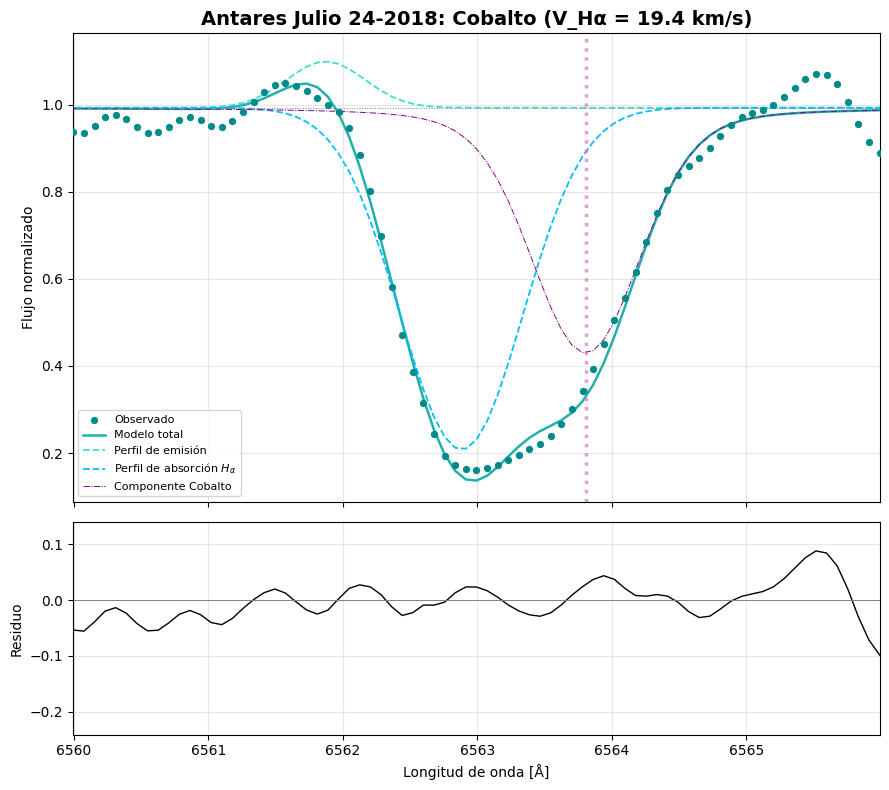

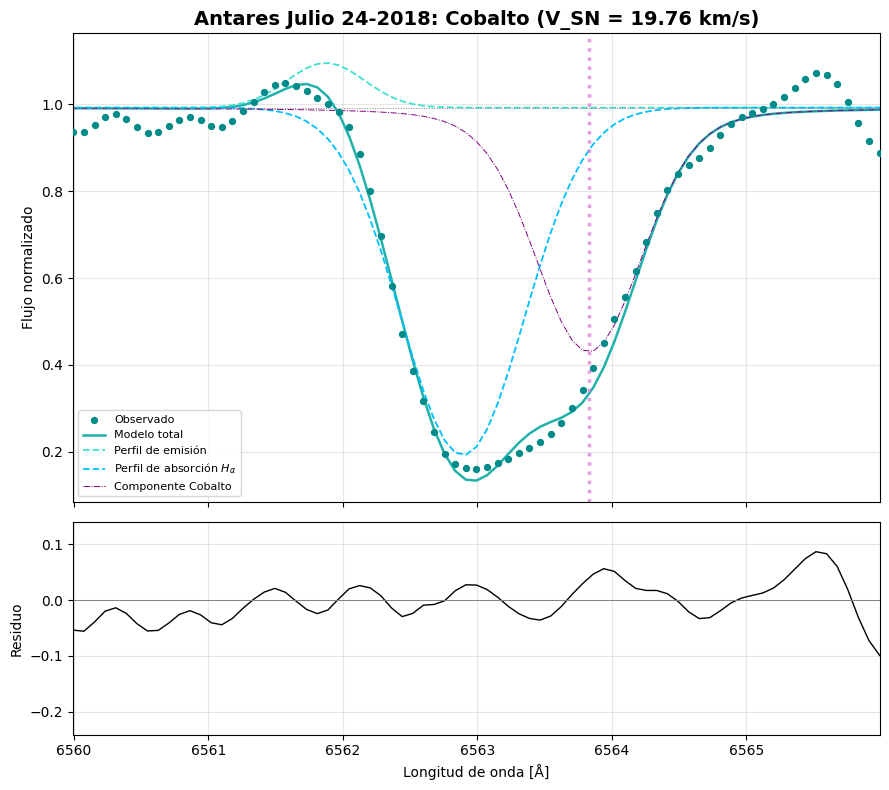

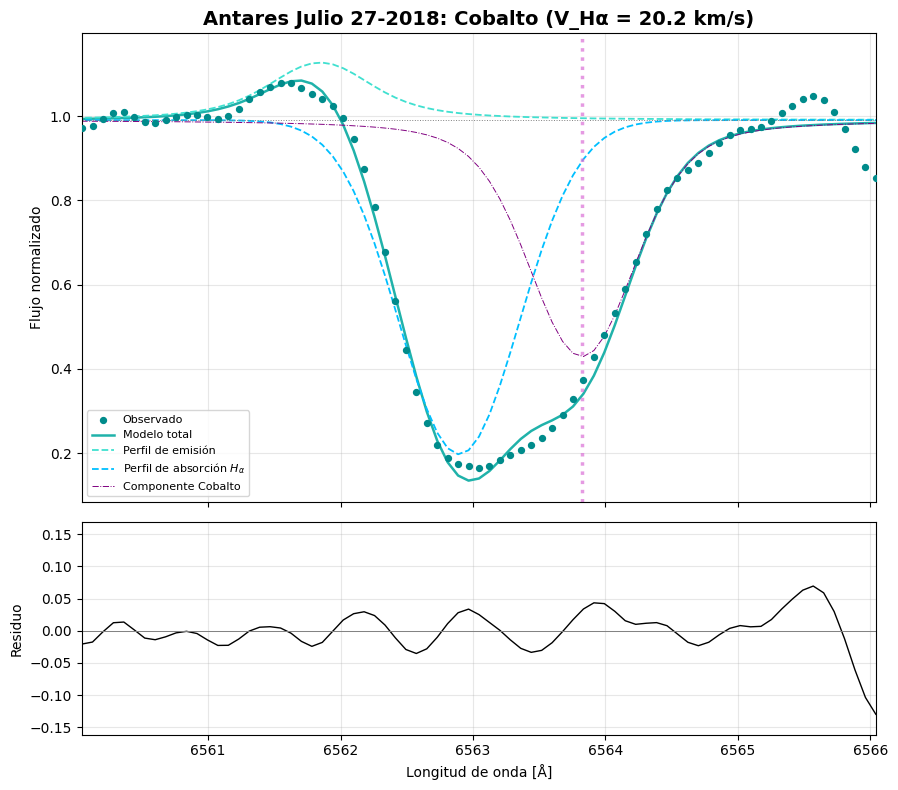

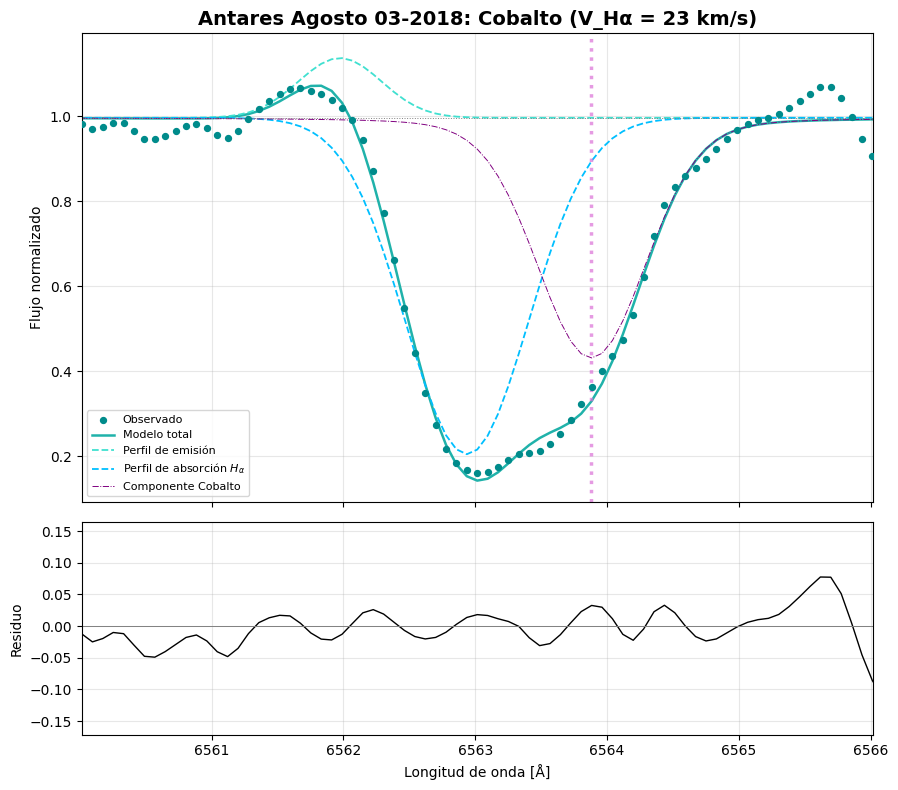

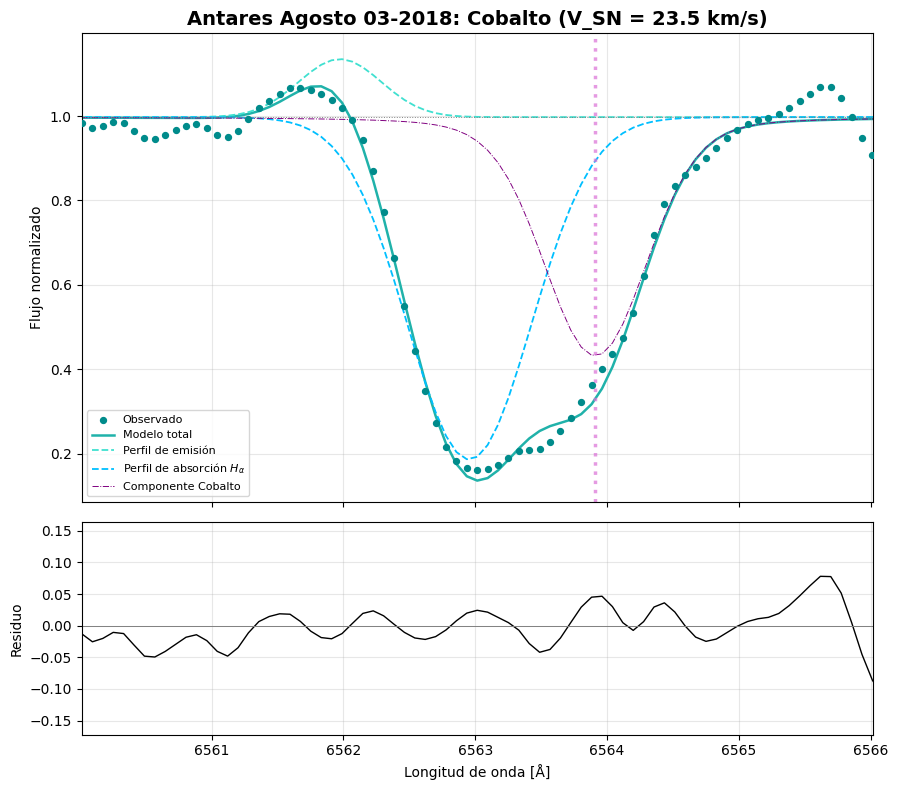

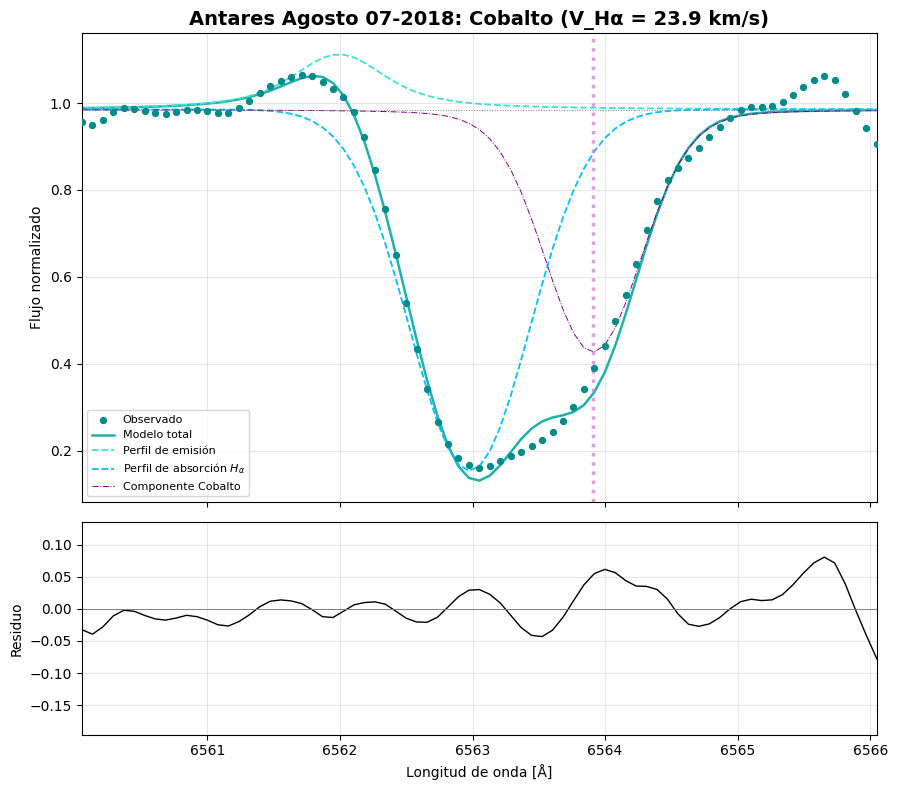

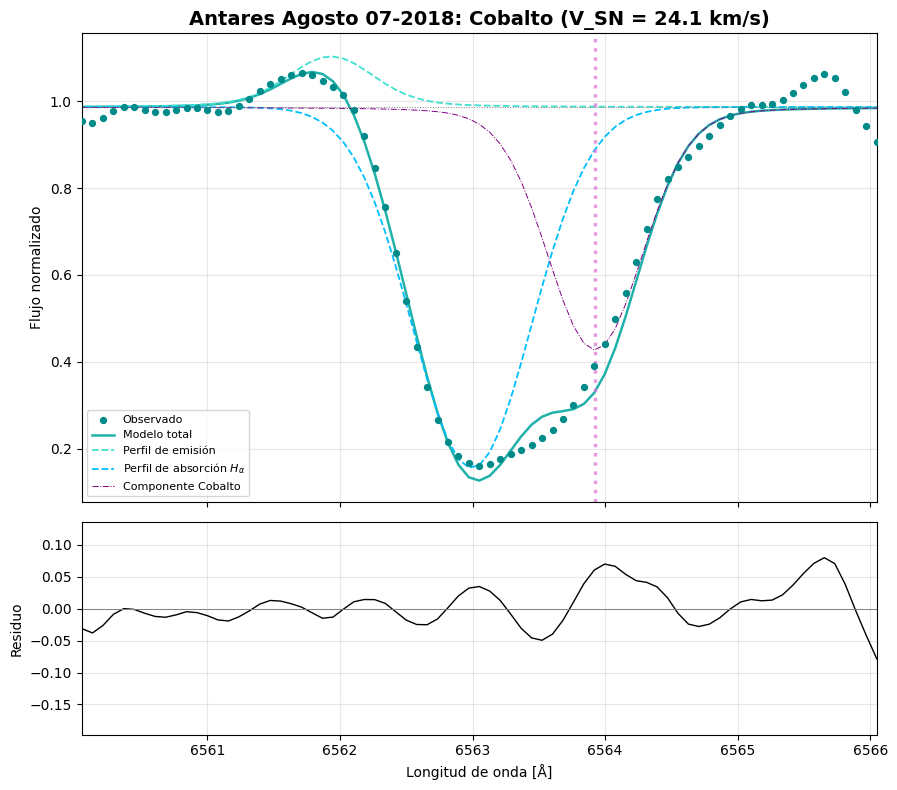

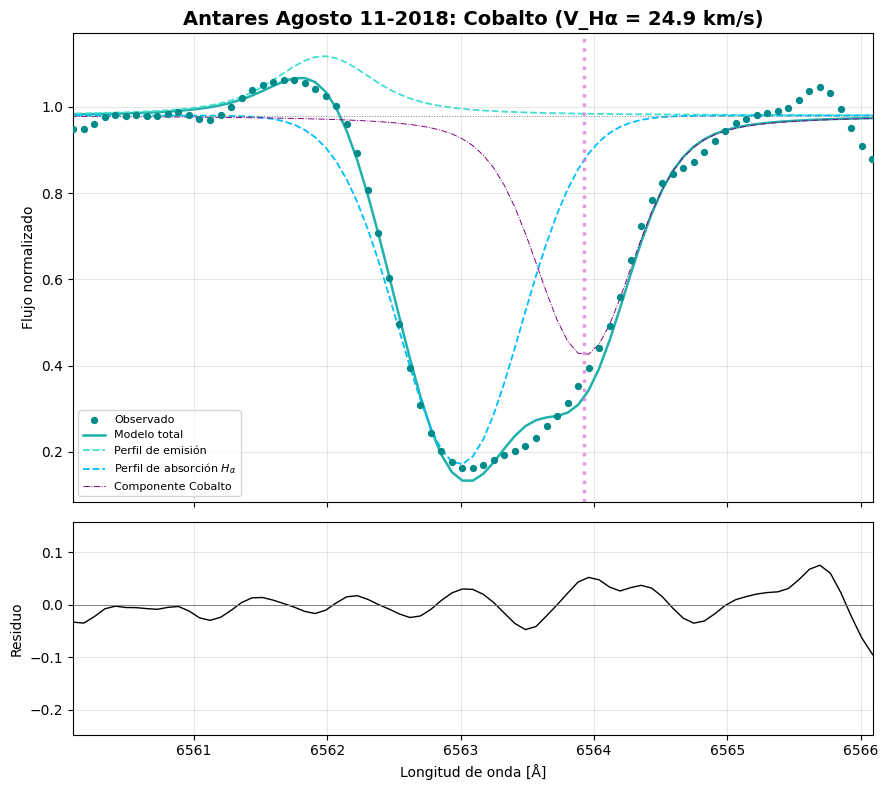

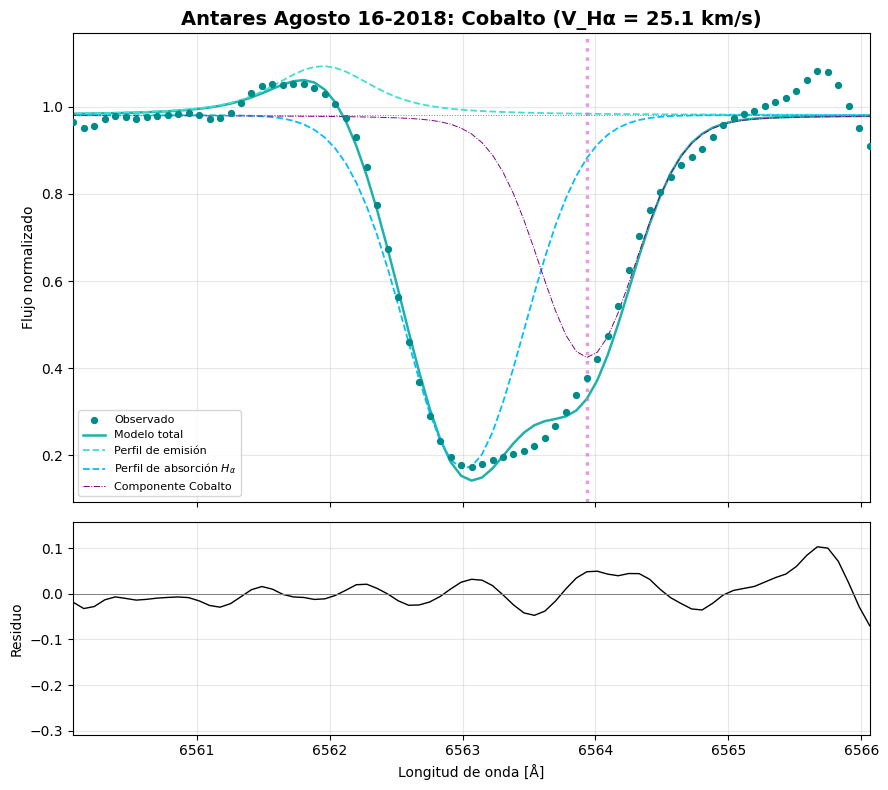

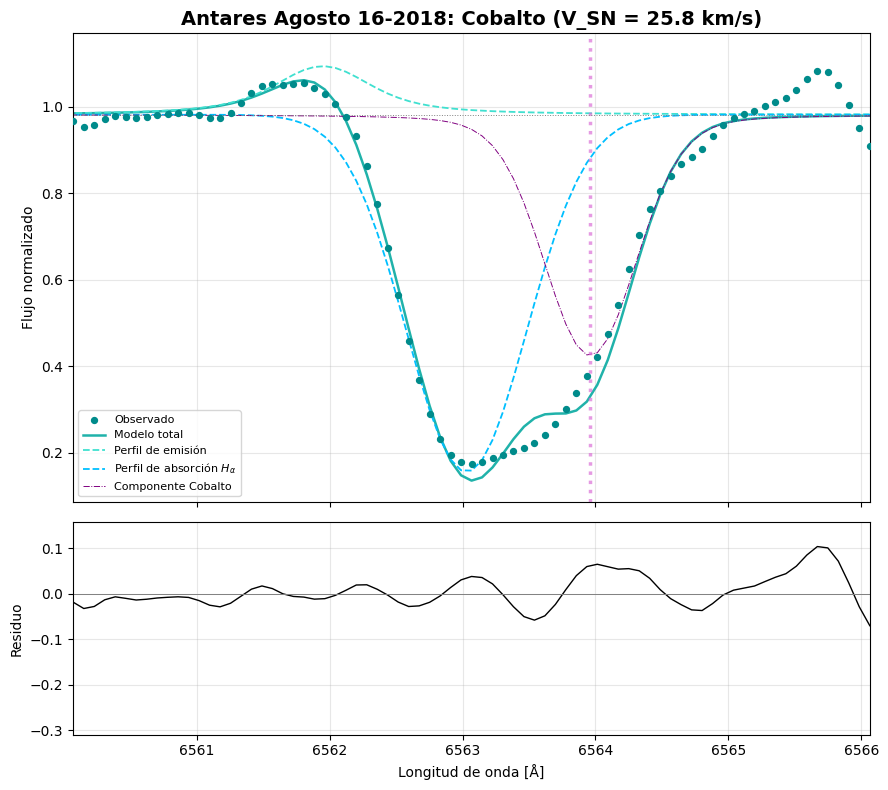

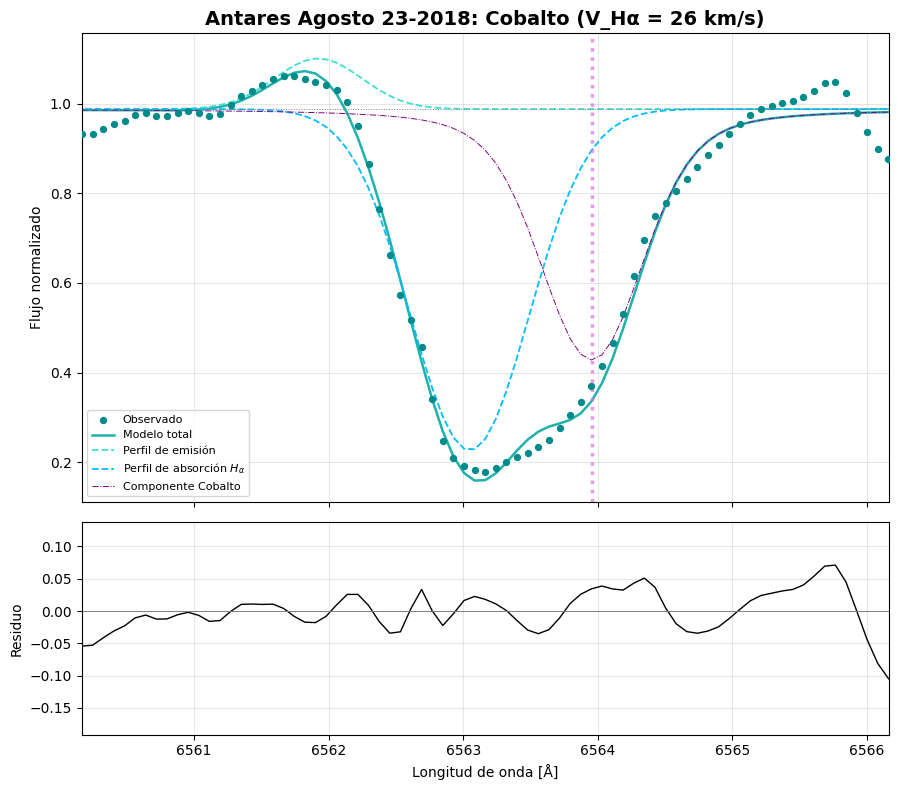

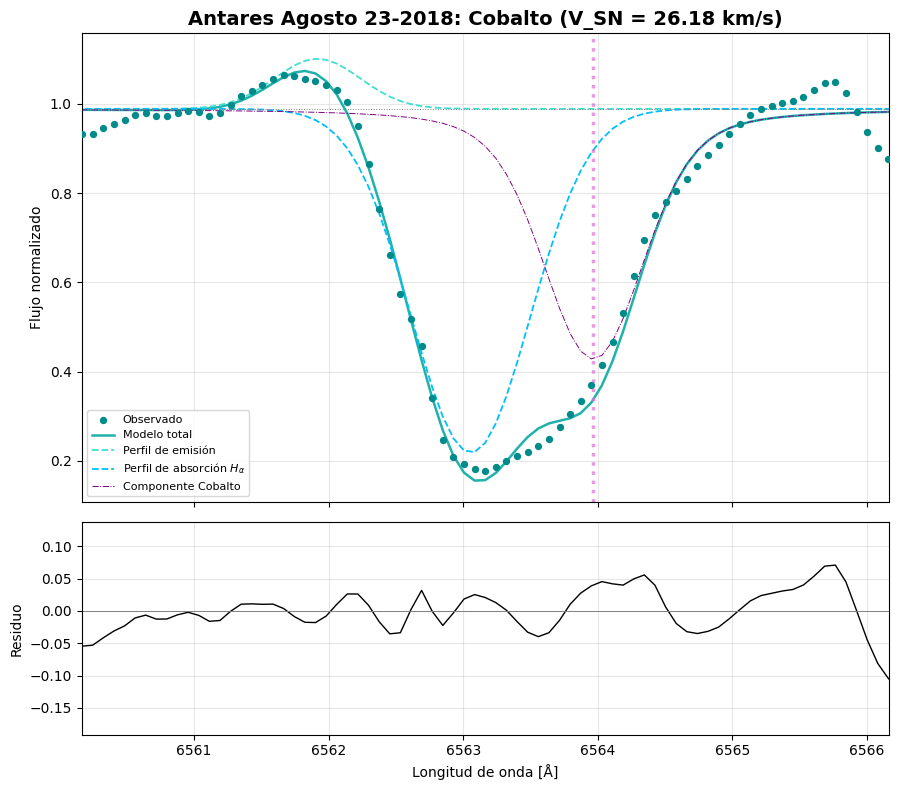

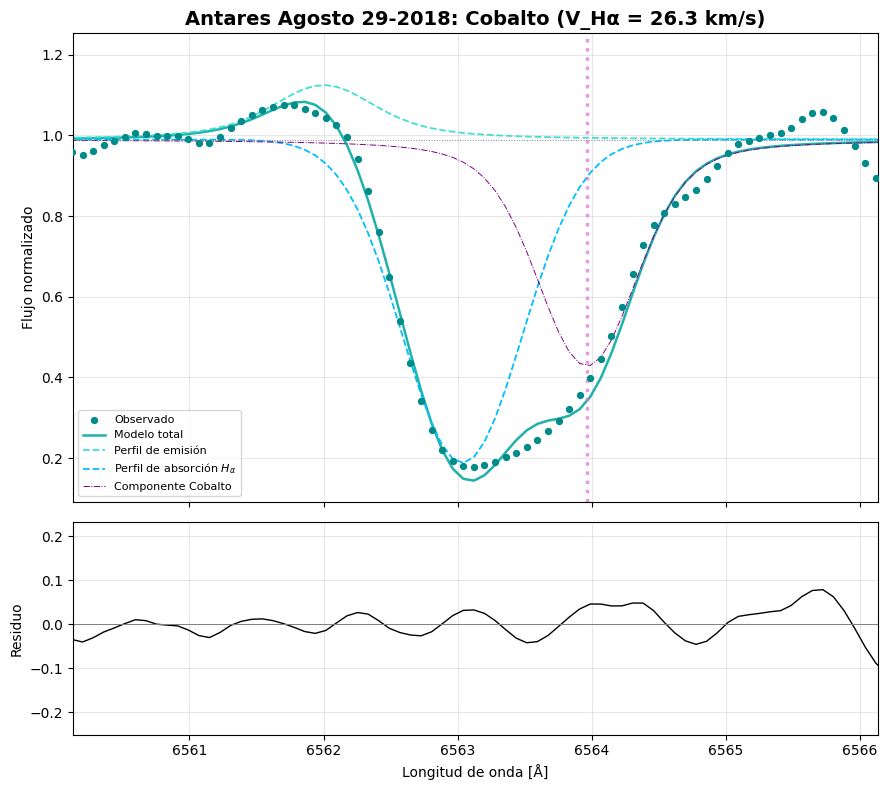

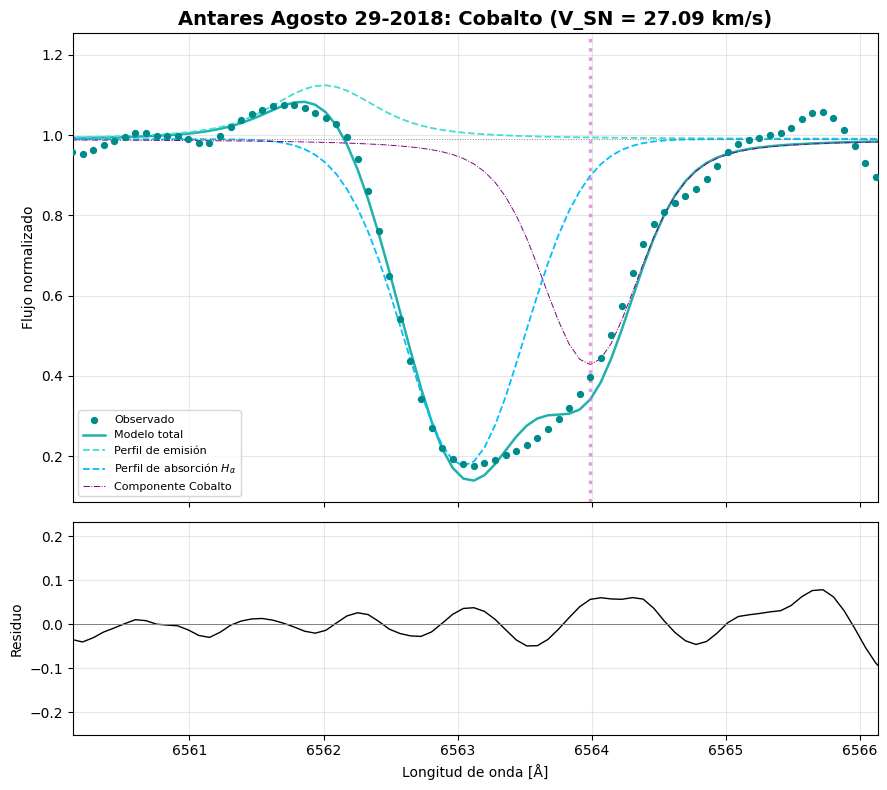

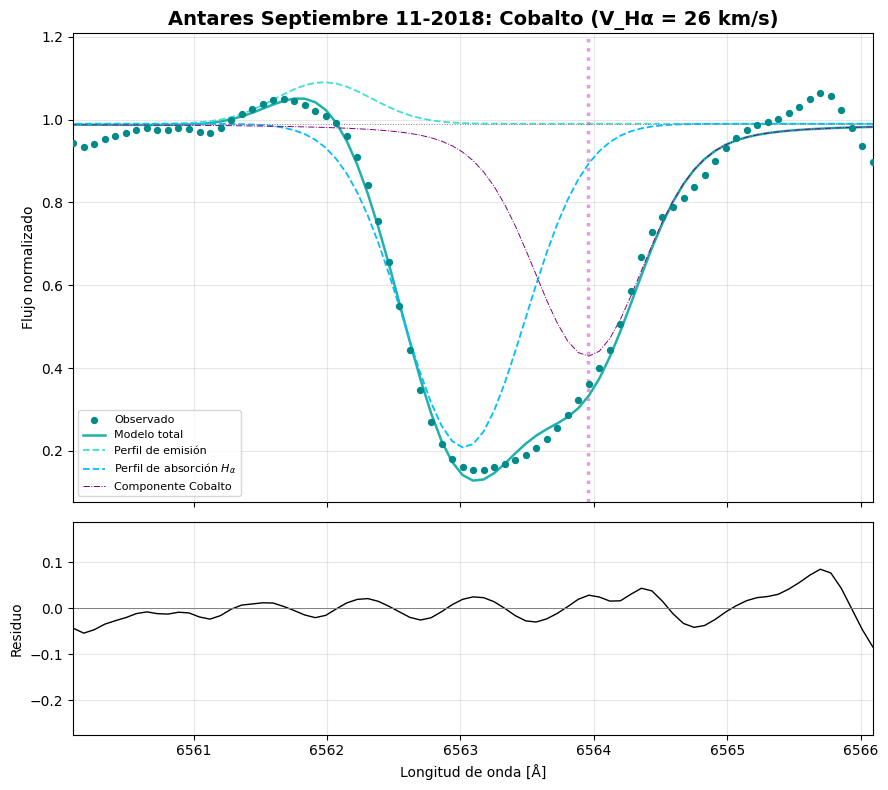

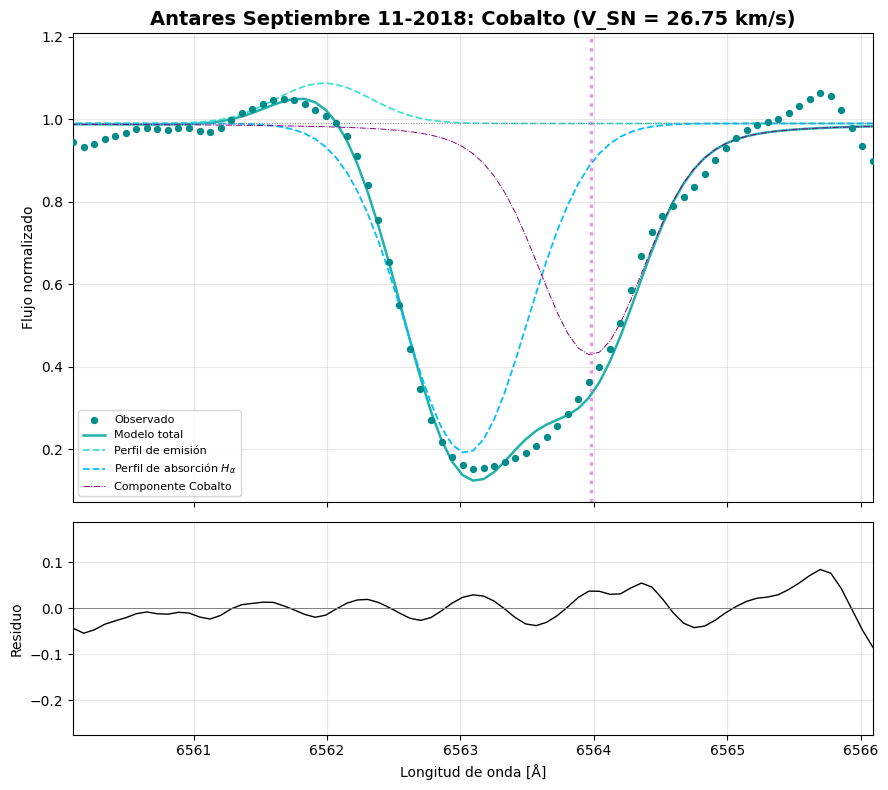

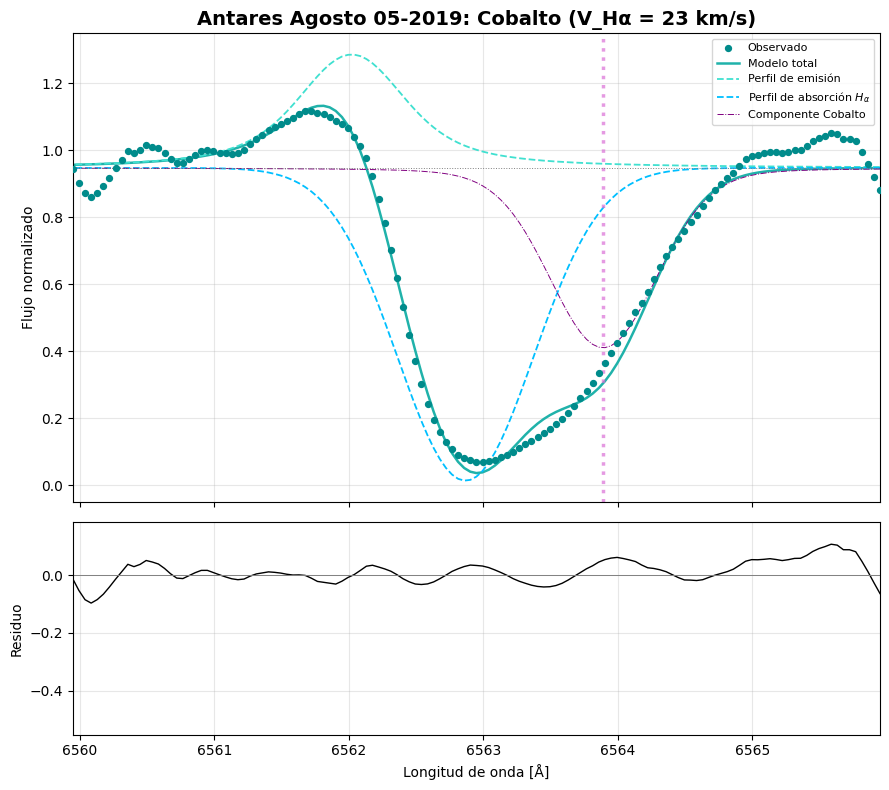

In [24]:
centro_lab_cobalto = 6563.397 #Angstroms

resultados = {}

for nombre, meta in metadatos.items():
    fecha_str = meta["fecha"]
    df = meta["datos"]          
    
    fits_fecha = {}

    # Ajuste velocidad alredor de Hα

    if meta.get("Velocidad Hα") is not None:
        v_halpha = meta["Velocidad Hα"]
        err_halpha = meta.get("Incertidumbre v Hα", 3.0)
        
        lineas_halpha = [{
            "nombre": "Cobalto",
            "centro": centro_lab_cobalto,
            "velocidad": v_halpha,
            "incertidumbre_v": err_halpha,
            "prof_ref": (0.55, 0.63),
            "t_ref": (3500, 4250),
        }]
        
        fits_fecha["Hα"] = fit_y_decomposicion(
            df, meta["centro_aprox"], "Longitud onda", "Flujo Normalizado",
            lineas_metalicas=lineas_halpha, teff=3660
        )
        
        visualizacion_con_metalica(
            fits_fecha["Hα"], lineas_halpha, f"{fecha_str}_Hα",
            titulo=f"Antares {fecha_str}: Cobalto (V_Hα = {v_halpha} km/s)",
            rango_x=(meta["centro_aprox"] - 3, meta["centro_aprox"] + 3)
        )

    # Ajuste velocidad alredor del Sector Naranja

    if meta.get("Velocidad Sector naranja") is not None:
        v_ir = meta["Velocidad Sector naranja"]
        err_ir = meta.get("Incertidumbre v Sector naranja", 3.0)
        
        lineas_ir = [{
            "nombre": "Cobalto",
            "centro": centro_lab_cobalto,
            "velocidad": v_ir,
            "incertidumbre_v": err_ir,
            "prof_ref": (0.55, 0.63),
            "t_ref": (3500, 4250),
        }]
        
        fits_fecha["Sector naranja"] = fit_y_decomposicion(
            df, meta["centro_aprox"], "Longitud onda", "Flujo Normalizado",
            lineas_metalicas=lineas_ir, teff=3660
        )
        
        visualizacion_con_metalica(
            fits_fecha["Sector naranja"], lineas_ir, f"{fecha_str}_Sector naranja",
            titulo=f"Antares {fecha_str}: Cobalto (V_SN = {v_ir} km/s)",
            rango_x=(meta["centro_aprox"] - 3, meta["centro_aprox"] + 3)
        )

    resultados[nombre] = fits_fecha

<h5 style="color: #e19edc;"> Gráfica Conjunta</sub></h5>

In [42]:
def visualizar_en_ax(res_metal, lineas_metalicas, titulo, rango_x=None, fig=None, gs=None, fila=0, columna=0,
                      centrado=False):

    longitud_onda = res_metal["longitud_onda"]
    flujo = res_metal["flujo"]
    fit = res_metal["fit"]
    comps = res_metal["comps"]
    continuo = comps["cont_"]

    if centrado:
        fila_gs = gs[fila, :].subgridspec(1, 3, width_ratios=[1, 2, 1], wspace=0.0)
        subgs = fila_gs[1].subgridspec(2, 1, height_ratios=[2.2, 1], hspace=0.05)
    else:
        subgs = gs[fila, columna].subgridspec(2, 1, height_ratios=[2.2, 1], hspace=0.05)

    ax = fig.add_subplot(subgs[0])
    ax2 = fig.add_subplot(subgs[1], sharex=ax)

    # Ocultar etiquetas del eje x en el panel superior
    ax.tick_params(labelbottom=False)

    # Panel Superior
    ax.scatter(longitud_onda, flujo, s=18, color="darkcyan", label="Observado", zorder=3)
    ax.plot(longitud_onda, fit.best_fit, color="lightseagreen", lw=1.8, label="Modelo total")
    ax.plot(longitud_onda, res_metal["perfil_emision"], "--", color="turquoise", lw=1.3, label="Perfil de emisión")
    ax.plot(longitud_onda, res_metal["perfil_absorcion"], "--", color="deepskyblue", lw=1.3,
            label=r"Perfil de absorción $H_\alpha$")

    for linea in lineas_metalicas:
        pref = f"{linea['nombre']}_"
        perfil_metal = continuo + comps[pref]
        ax.plot(longitud_onda, perfil_metal, "-.", color="purple", lw=0.7, label=f"Componente {linea['nombre']}")
        ax.axvline(fit.params[f"{pref}center"].value, color="orchid", lw=2.5, ls=":", alpha=0.7)

    # Continuo
    ax.axhline(continuo[0], color="gray", lw=0.7, ls=":")
    ax.set_ylabel("Flujo normalizado")
    ax.set_title(titulo, fontsize=11, fontweight="bold", pad=6)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)

    ax2.plot(longitud_onda, res_metal["residuo"], color="black", lw=1)
    ax2.axhline(0, color="gray", lw=0.7)
    ax2.set_xlabel("Longitud de onda [Å]")
    ax2.set_ylabel("Residuo")
    ax2.grid(alpha=0.3)

    if rango_x is not None:
        ax.set_xlim(rango_x)

    return ax, ax2

def _margen_superior(alto_fig, margen_titulo_in=0.65, margen_superior_in=0.15):
    top = 1 - margen_titulo_in / alto_fig
    y_supertitulo = 1 - margen_superior_in / alto_fig
    return top, y_supertitulo

In [51]:
def crear_figura_2018(fechas_bloque, datos_anio, carpeta_salida=None, sufijo=""):
 
    n_filas = len(fechas_bloque)
 
    if n_filas == 0:
        return None
 
    alto_fila = 5.2
    alto_fig = alto_fila * n_filas
 
    fig = plt.figure(figsize=(16, alto_fig))
    gs = GridSpec(n_filas, 2, figure=fig, hspace=0.45, wspace=0.15)
 
    for fila, fecha in enumerate(fechas_bloque):
 
        datos_fecha = datos_anio[fecha]
 
        tiene_halpha = "Hα" in datos_fecha
        tiene_sector = "Sector naranja" in datos_fecha
 
        # Hα + Sector naranja
        if tiene_halpha and tiene_sector:
 
            datos = datos_fecha["Hα"]
            visualizar_en_ax(datos["res"], datos["lineas"], datos["titulo"], datos["rango_x"],
                              fig=fig, gs=gs, fila=fila, columna=0, centrado=False)
 
            datos = datos_fecha["Sector naranja"]
            visualizar_en_ax(datos["res"], datos["lineas"], datos["titulo"], datos["rango_x"],
                              fig=fig, gs=gs, fila=fila, columna=1, centrado=False)
 
        # Solo Hα
        elif tiene_halpha:
 
            datos = datos_fecha["Hα"]
            visualizar_en_ax(datos["res"], datos["lineas"], datos["titulo"], datos["rango_x"],
                              fig=fig, gs=gs, fila=fila, columna=0, centrado=True)
 
        # Solo Sector naranja
        elif tiene_sector:
 
            datos = datos_fecha["Sector naranja"]
            visualizar_en_ax(datos["res"], datos["lineas"], datos["titulo"], datos["rango_x"],
                              fig=fig, gs=gs, fila=fila, columna=0, centrado=True)
 
    top, y_sup = _margen_superior(alto_fig)
 
    titulo_fig = r"Modelamiento sector Hα — 2018" + (f" ({sufijo.strip('_').replace('parte', 'parte ')})"
                                                       if sufijo else "")
 
    fig.suptitle(titulo_fig, fontsize=18, fontweight="bold", y=y_sup)
    fig.subplots_adjust(top=top, bottom=0.04, left=0.06, right=0.98)
 
    if carpeta_salida is not None:
        ruta = (carpeta_salida + fr"\comparacion_sector_Halpha_2018{sufijo}.png")
        fig.savefig(ruta, dpi=300, bbox_inches="tight")
        print(f"Figura 2018{sufijo} guardada en:\n{ruta}")
 
    plt.show()
    return fig
 
 
def generar_figuras_2018(datos_anio, carpeta_salida=None, max_filas=4):
 
    fechas = list(datos_anio.keys())
 
    if len(fechas) == 0:
        return []
 
    n_bloques = int(np.ceil(len(fechas) / max_filas))
    figuras = []
 
    for idx in range(n_bloques):
 
        bloque = fechas[idx * max_filas: (idx + 1) * max_filas]
        sufijo = f"_parte{idx + 1}" if n_bloques > 1 else ""
 
        fig = crear_figura_2018(bloque, datos_anio, carpeta_salida=carpeta_salida, sufijo=sufijo)
        figuras.append(fig)
 
    return figuras

In [52]:
def crear_figura_2019(fechas_bloque, datos_anio, carpeta_salida=None, sufijo=""):
 
    n_items = len(fechas_bloque)
 
    if n_items == 0:
        return None
 
    n_filas = int(np.ceil(n_items / 2))
    alto_fila = 5.5
    alto_fig = alto_fila * n_filas
 
    fig = plt.figure(figsize=(16, alto_fig))
    gs = GridSpec(n_filas, 2, figure=fig, hspace=0.45, wspace=0.15)
 
    for i, fecha in enumerate(fechas_bloque):
 
        fila = i // 2
        columna = 0 if i % 2 == 0 else 1
 
        datos = datos_anio[fecha]["Hα"]
 
        es_ultima = (i == n_items - 1)
        es_impar = (n_items % 2 == 1)
 
        if es_ultima and es_impar:
            visualizar_en_ax(datos["res"], datos["lineas"], datos["titulo"], datos["rango_x"],
                              fig=fig, gs=gs, fila=fila, columna=0, centrado=True)
        else:
            visualizar_en_ax(datos["res"], datos["lineas"], datos["titulo"], datos["rango_x"],
                              fig=fig, gs=gs, fila=fila, columna=columna, centrado=False)
 
    top, y_sup = _margen_superior(alto_fig)
 
    titulo_fig = r"Modelamiento sector Hα — 2019" + (f" ({sufijo.strip('_').replace('parte', 'parte ')})"
                                                       if sufijo else "")
 
    fig.suptitle(titulo_fig, fontsize=18, fontweight="bold", y=y_sup)
    fig.subplots_adjust(top=top, bottom=0.04, left=0.06, right=0.98, hspace=0.45, wspace=0.15)
 
    if carpeta_salida is not None:
        ruta = (carpeta_salida + fr"\comparacion_sector_Halpha_2019{sufijo}.png")
        fig.savefig(ruta, dpi=300, bbox_inches="tight")
        print(f"Figura 2019{sufijo} guardada en:\n{ruta}")
 
    plt.show()
    return fig
 
 
def generar_figuras_2019(datos_anio, carpeta_salida=None, max_filas=4):
 
    fechas_halpha = [f for f in datos_anio if "Hα" in datos_anio[f]]
 
    if len(fechas_halpha) == 0:
        return []
 
    tam_bloque = max_filas * 2
    n_bloques = int(np.ceil(len(fechas_halpha) / tam_bloque))
    figuras = []
 
    for idx in range(n_bloques):
 
        bloque = fechas_halpha[idx * tam_bloque: (idx + 1) * tam_bloque]
        sufijo = f"_parte{idx + 1}" if n_bloques > 1 else ""
 
        fig = crear_figura_2019(bloque, datos_anio, carpeta_salida=carpeta_salida, sufijo=sufijo)
        figuras.append(fig)
 
    return figuras

In [53]:
centro_lab_cobalto = 6563.397  # Angstroms

resultados = {}

visualizaciones_por_anio = {}

for nombre, meta in metadatos.items():

    fecha_str = meta["fecha"]

    df = meta["datos"]

    fits_fecha = {}

    anio = fecha_str[-4:]

    if anio not in visualizaciones_por_anio:

        visualizaciones_por_anio[anio] = {}


    if fecha_str not in visualizaciones_por_anio[anio]:

        visualizaciones_por_anio[anio][fecha_str] = {}

    # Velocidad sector Hα


    if meta.get("Velocidad Hα") is not None:

        v_halpha = meta["Velocidad Hα"]

        err_halpha = meta.get("Incertidumbre v Hα", 3.0)

        # Cobalto

        lineas_halpha = [{
            "nombre": "Cobalto",
            "centro": centro_lab_cobalto,
            "velocidad": v_halpha,
            "incertidumbre_v": err_halpha,
            "prof_ref": (0.55, 0.63),
            "t_ref": (3500, 4250),
        }]

        # Ajuste

        fits_fecha["Hα"] = fit_y_decomposicion(df, meta["centro_aprox"], "Longitud onda", "Flujo Normalizado",
                                                lineas_metalicas = lineas_halpha,teff = 3660)

        visualizaciones_por_anio[anio][fecha_str]["Hα"] = {

            "res": fits_fecha["Hα"],

            "lineas": lineas_halpha,

            "titulo": (
                f"Antares {fecha_str}: "
                f"Cobalto "
                f"($V_{{H\\alpha}}$ = "
                f"{v_halpha} km/s)"
            ),

            "rango_x": (
                meta["centro_aprox"] - 3,
                meta["centro_aprox"] + 3
            )
        }


    # Velocidad sector Naranja

    if meta.get("Velocidad Sector naranja") is not None:

        v_ir = meta["Velocidad Sector naranja"]

        err_ir = meta.get("Incertidumbre v Sector naranja", 3.0)

        # Cobalto

        lineas_ir = [{
            "nombre": "Cobalto",
            "centro": centro_lab_cobalto,
            "velocidad": v_ir,
            "incertidumbre_v": err_ir,
            "prof_ref": (0.55, 0.63),
            "t_ref": (3500, 4250),
        }]

        # Ajuste

        fits_fecha["Sector naranja"] = fit_y_decomposicion(df, meta["centro_aprox"], "Longitud onda", "Flujo Normalizado",
                                                           lineas_metalicas=lineas_ir, teff=3660)

        visualizaciones_por_anio[anio][fecha_str]["Sector naranja"] = {

            "res": fits_fecha["Sector naranja"],

            "lineas": lineas_ir,

            "titulo": (
                f"Antares {fecha_str}: "
                f"Cobalto "
                f"($V_{{SN}}$ = "
                f"{v_ir} km/s)"
            ),

            "rango_x": (
                meta["centro_aprox"] - 3,
                meta["centro_aprox"] + 3
            )
        }

    resultados[nombre] = fits_fecha

carpeta_salida = (r"Graficas 2018 y 2019\Modelamiento")

Figura 2018_parte1 guardada en:
Graficas 2018 y 2019\Modelamiento\comparacion_sector_Halpha_2018_parte1.png


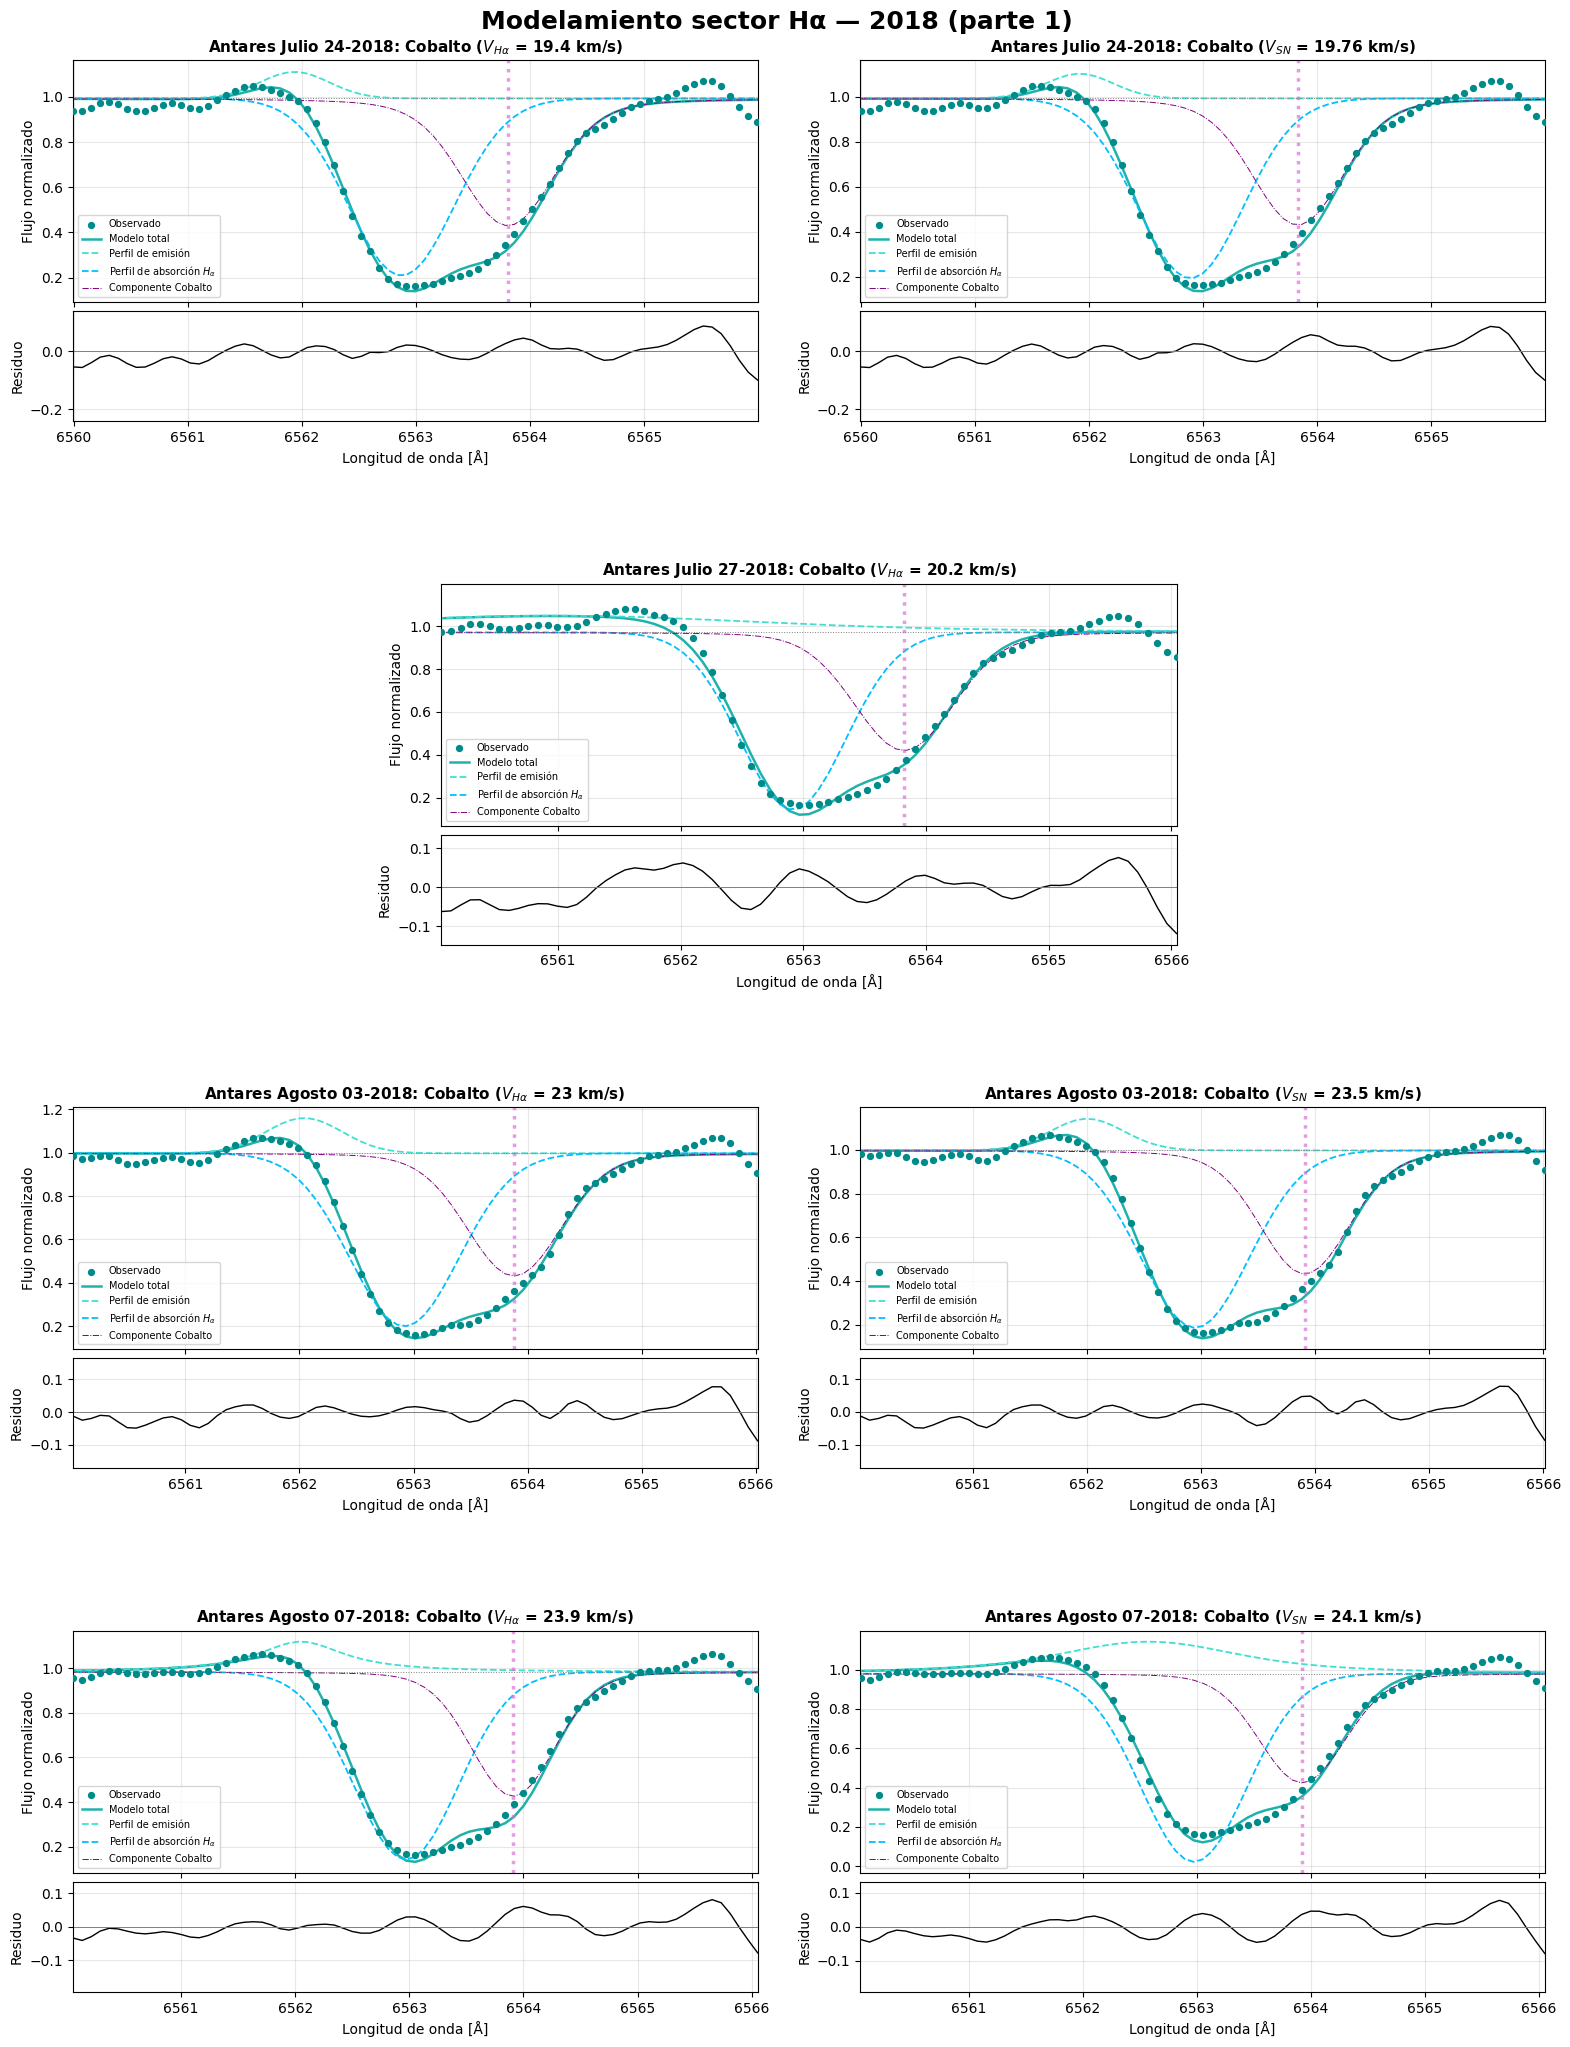

Figura 2018_parte2 guardada en:
Graficas 2018 y 2019\Modelamiento\comparacion_sector_Halpha_2018_parte2.png


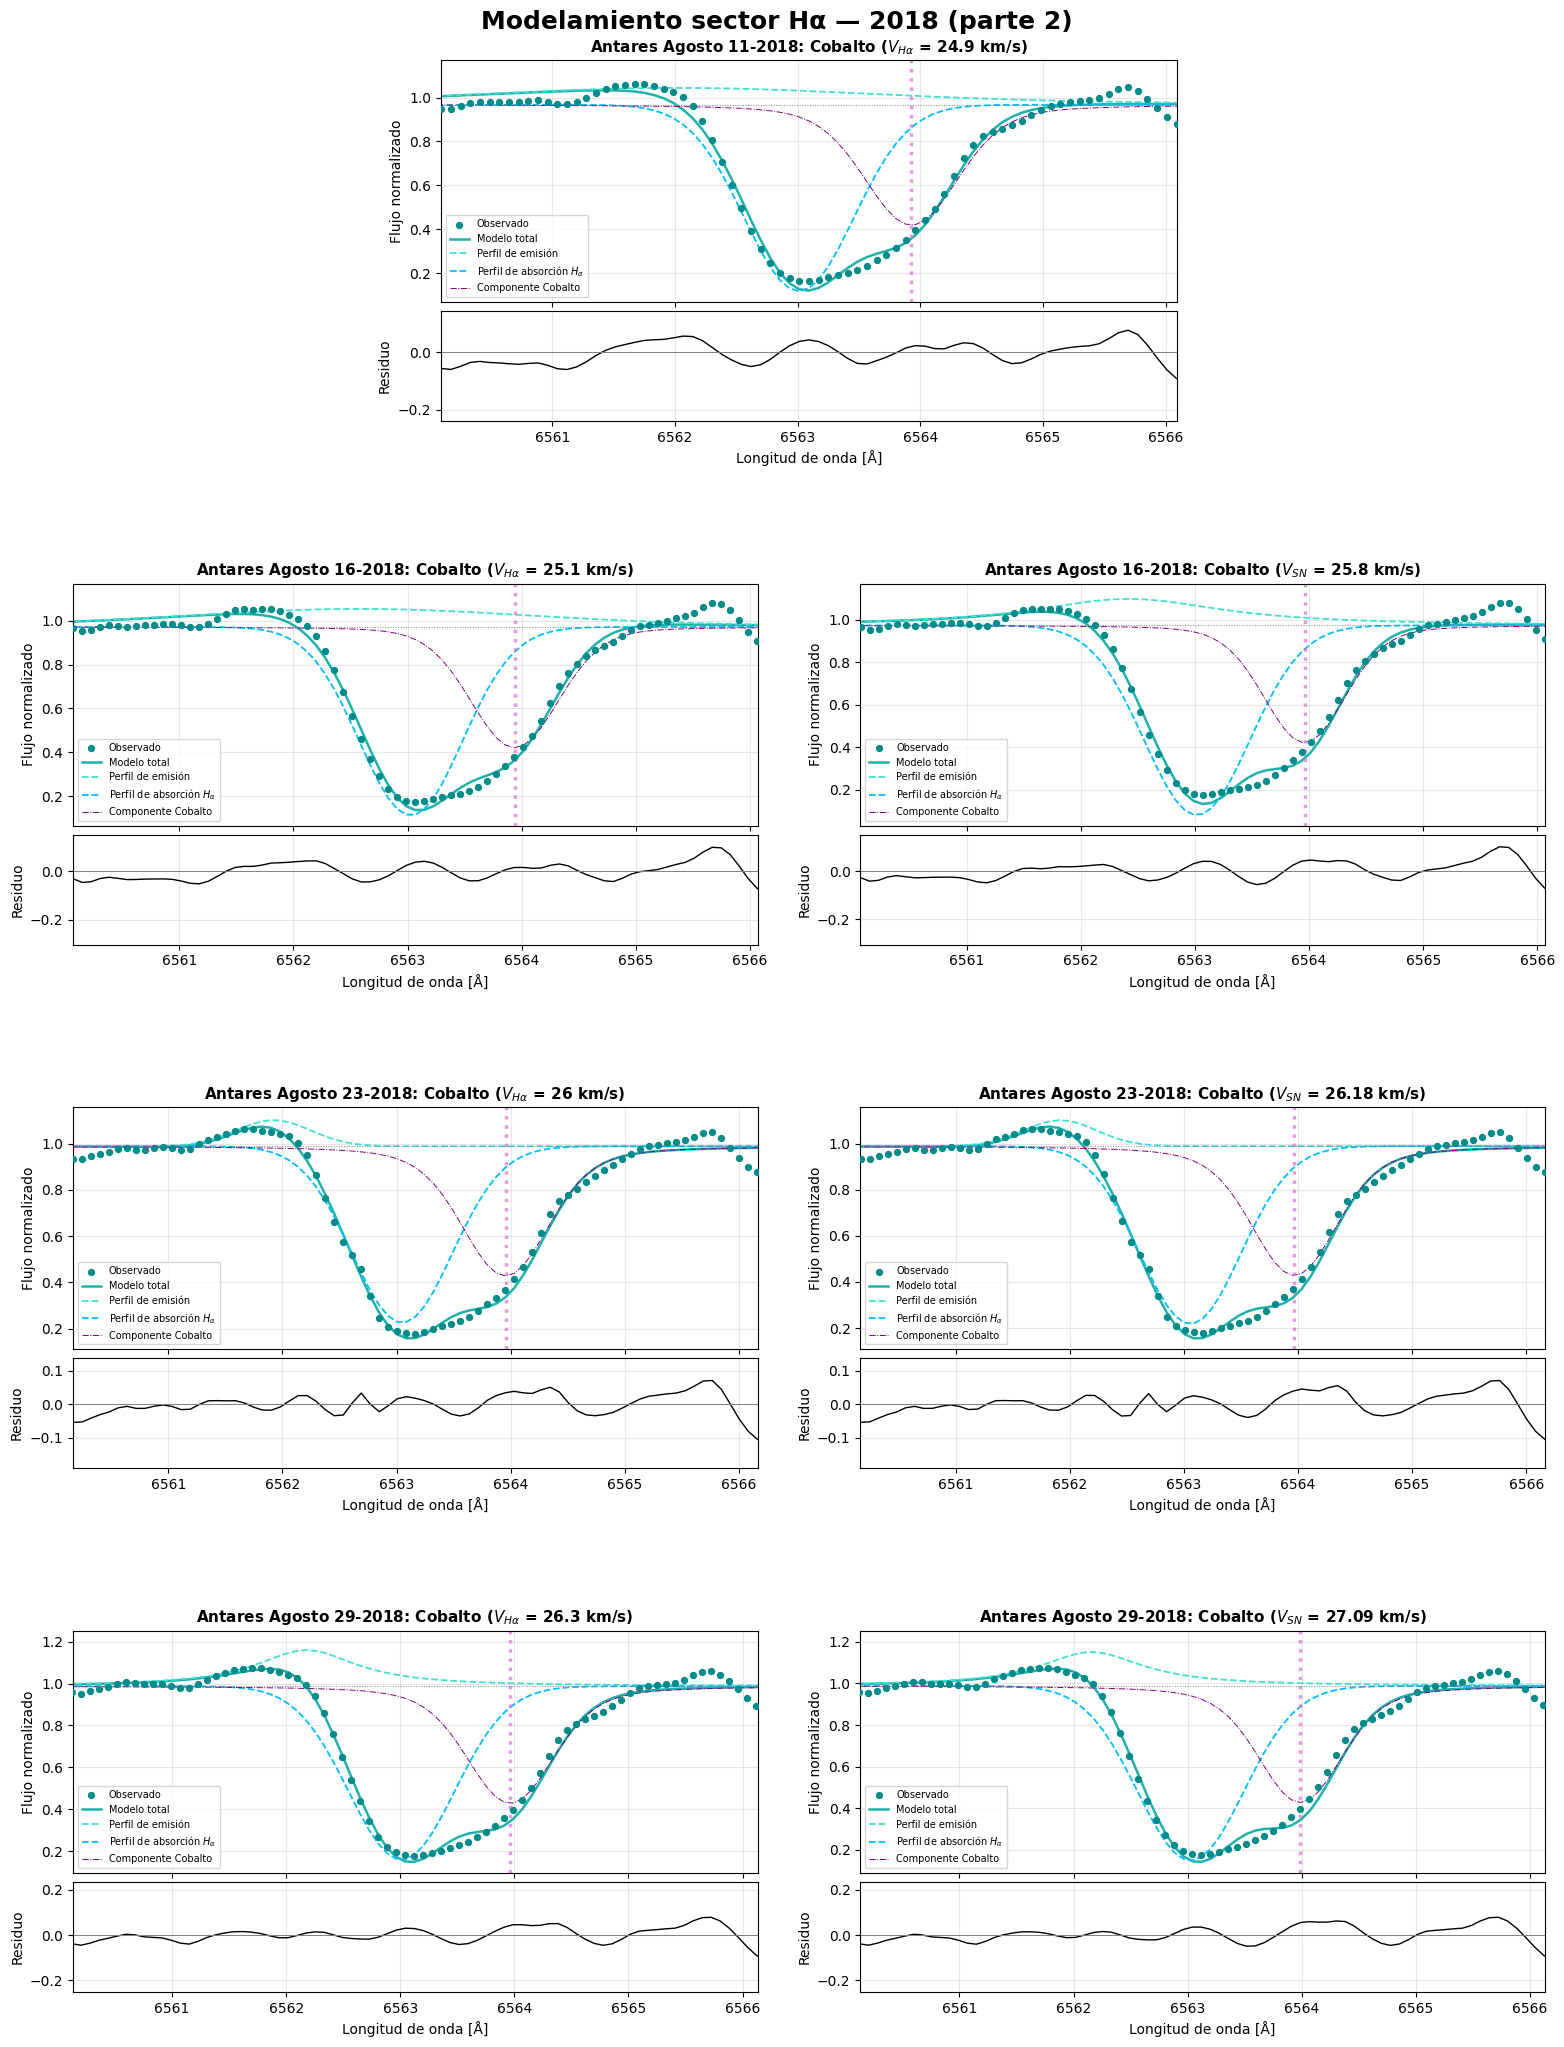

Figura 2018_parte3 guardada en:
Graficas 2018 y 2019\Modelamiento\comparacion_sector_Halpha_2018_parte3.png


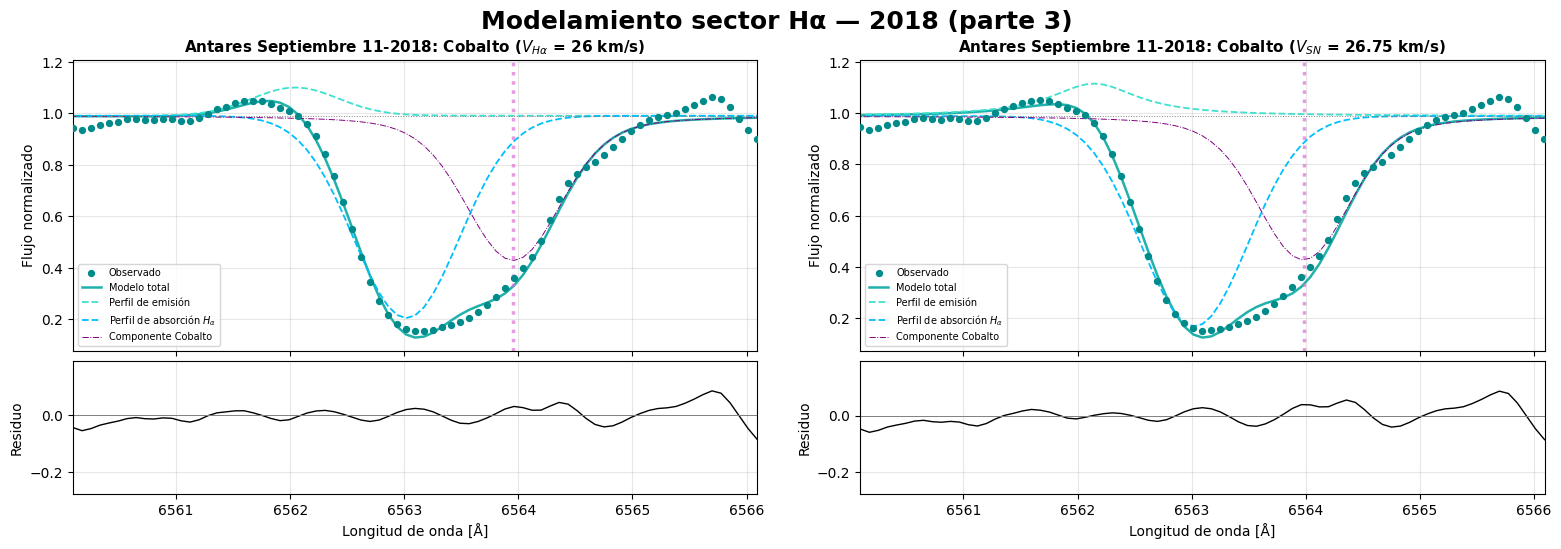

Figura 2019 guardada en:
Graficas 2018 y 2019\Modelamiento\comparacion_sector_Halpha_2019.png


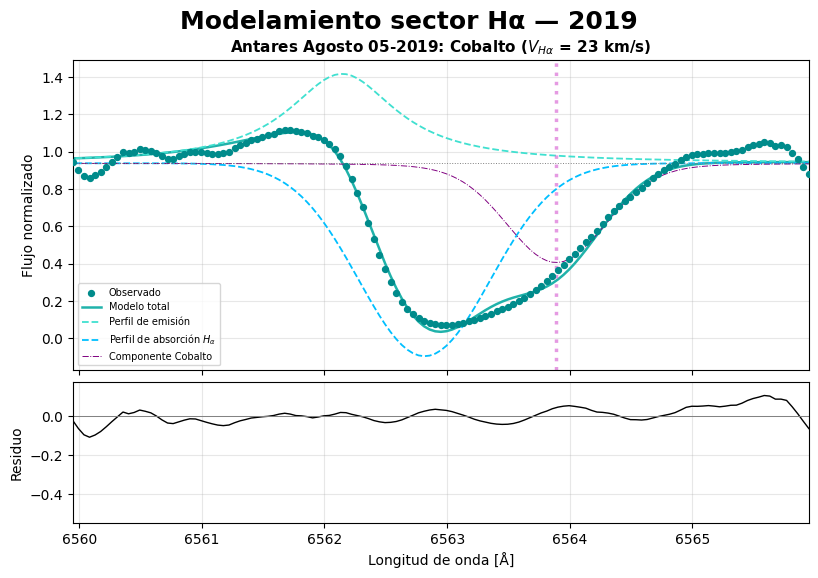

In [58]:
if "2018" in visualizaciones_por_anio:

    generar_figuras_2018(visualizaciones_por_anio["2018"], carpeta_salida = carpeta_salida, max_filas = 4)

if "2019" in visualizaciones_por_anio:

    generar_figuras_2019(visualizaciones_por_anio["2019"], carpeta_salida=carpeta_salida, max_filas = 4)


<h4 style="color: #e19edc;"> Mejor ajuste teniendo en cuenta la resolución de ESPARTACO I y Chi cuadrado </h4>

In [36]:
filas_chi2 = []

for nombre, fits_fecha in resultados.items():
    fecha_etiqueta = metadatos[nombre].get("fecha", nombre)
    
    # Chi del visible
    chi2_vis = fits_fecha["Hα"]["fit"].chisqr if "Hα" in fits_fecha else None
    
    # Chi del Sector naranja (si existe)
    chi2_ir = fits_fecha["Sector naranja"]["fit"].chisqr if "Sector naranja" in fits_fecha else "No existe"
    
    filas_chi2.append({
        "Fecha": fecha_etiqueta,
        "χ² (Hα)": round(chi2_vis, 4) if isinstance(chi2_vis, (int, float)) else chi2_vis,
        "χ² (SN)": round(chi2_ir, 4) if isinstance(chi2_ir, (int, float)) else chi2_ir,
        "Incertidumbre v Hα [km/s]": metadatos[nombre].get("Incertidumbre v Hα", "No existe"),
        "Incertidumbre v SN [km/s]": metadatos[nombre].get("Incertidumbre v Sector naranja", "No existe")
    })

tabla_chi2 = pd.DataFrame(filas_chi2)

display(tabla_chi2)

,Fecha,χ² (Hα),χ² (SN),Incertidumbre v Hα [km/s],Incertidumbre v SN [km/s]
0,Julio 24-2018,0.7557,0.763,0.7,0.05
1,Julio 27-2018,0.3863,No existe,0.8,No existe
2,Agosto 03-2018,0.4434,0.4504,0.9,0.03
3,Agosto 07-2018,0.4005,0.4074,0.5,0.04
4,Agosto 11-2018,0.4815,No existe,0.7,No existe
5,Agosto 16-2018,0.5306,0.5376,0.4,0.06
6,Agosto 23-2018,0.4151,0.4201,0.5,0.11
7,Agosto 29-2018,0.9725,0.9849,0.4,0.15
8,Septiembre 11-2018,0.9369,0.9455,0.5,0.09
9,Agosto 05-2019,2.2336,No existe,0.5,No existe


In [37]:
tabla_chi2.to_excel(fr"Parámetros para análisis de Antares\Comparación chi cuadrado espectros del 2018 y 2019.xlsx", index=False)



<h5 style="color: #e19edc;"> Ambos espectros presentan una calidad de ajuste muy similar según el χ², pero el Sector Naranja proporciona velocidades con incertidumbres considerablemente menores.</h5>

In [ ]:
correcciones_velocidades = {m["fecha"]: m.get("Velocidad Telurica", 0.0) for m in metadatos.values()}

In [38]:
h_alpha_natural = 6562.812
cobalto_natural = centro_lab_cobalto

resultados_perfiles_halpha_y_cobalto_r = []

for fecha, fits_fecha in resultados.items():

    fecha_etiqueta = metadatos[fecha].get("fecha", fecha)
    meta_fecha = metadatos[fecha]

    if "Velocidad Sector naranja" in meta_fecha:
        sector_usado = "Sector naranja"
    else:
        sector_usado = "Hα"

    if sector_usado not in fits_fecha:
        raise KeyError(
            f"La fecha '{fecha}' debería usar el sector '{sector_usado}' según metadatos, "
            f"pero no se encontró en fits_fecha. Claves disponibles: {list(fits_fecha.keys())}"
        )

    mejor_clave = sector_usado
    res = fits_fecha[mejor_clave]

    # Extraer parámetros
    p = res["fit"].params
    comps = res["comps"]
    longitud_onda = res["longitud_onda"]
    continuo = comps["cont_"]

    # 1. PERFIL DE EMISIÓN AZUL
    c_em = p["em_azul_center"].value
    fwhm_em = p["em_azul_fwhm"].value
    amp_em = p["em_azul_height"].value

    z_em = (c_em - h_alpha_natural) / h_alpha_natural
    v_em = z_em * c_kms_s

    perfil_em_puro = comps["em_azul_"]
    ew_em = np.trapezoid(perfil_em_puro / continuo, longitud_onda)

    resultados_perfiles_halpha_y_cobalto_r.append({
        "Época": fecha_etiqueta,
        "Ajuste Seleccionado": mejor_clave,
        "Componente": "Emisión Azul Hα",
        "Centro [Å]": round(c_em, 3),
        "z": round(z_em, 6),
        "Velocidad [km/s]": round(v_em, 4),
        "Profundidad / Altura": round(amp_em, 4),
        "FWHM [Å]": round(fwhm_em, 3),
        "EW [Å]": round(ew_em, 4)
    })

    # 2. PERFIL DE ABSORCIÓN H_ALPHA
    c_abs = p["valle_abs_center"].value
    fwhm_abs = p["valle_abs_fwhm"].value
    prof_abs = abs(p["valle_abs_height"].value)

    z_abs = (c_abs - h_alpha_natural) / h_alpha_natural
    v_abs = z_abs * c_kms_s

    perfil_abs_puro = comps["valle_abs_"]
    ew_abs = np.trapezoid(abs(perfil_abs_puro) / continuo, longitud_onda)

    resultados_perfiles_halpha_y_cobalto_r.append({
        "Época": fecha_etiqueta,
        "Ajuste Seleccionado": mejor_clave,
        "Componente": "Absorción Hα",
        "Centro [Å]": round(c_abs, 3),
        "z": round(z_abs, 6),
        "Velocidad [km/s]": round(v_abs, 4),
        "Profundidad / Altura": round(prof_abs, 4),
        "FWHM [Å]": round(fwhm_abs, 3),
        "EW [Å]": round(ew_abs, 4)
    })

    # 3. LÍNEA DE COBALTO
    c_co = p["Cobalto_center"].value
    fwhm_co = p["Cobalto_fwhm"].value
    prof_co = abs(p["Cobalto_height"].value)

    z_co = (c_co - cobalto_natural) / cobalto_natural
    v_co = z_co * c_kms_s

    perfil_co_puro = comps["Cobalto_"]
    ew_co = np.trapezoid(abs(perfil_co_puro) / continuo, longitud_onda)

    resultados_perfiles_halpha_y_cobalto_r.append({
        "Época": fecha_etiqueta,
        "Ajuste Seleccionado": mejor_clave,
        "Componente": "Absorción Cobalto",
        "Centro [Å]": round(c_co, 3),
        "z": round(z_co, 6),
        "Velocidad [km/s]": round(v_co, 4),
        "Profundidad / Altura": round(prof_co, 4),
        "FWHM [Å]": round(fwhm_co, 3),
        "EW [Å]": round(ew_co, 4)
    })

tabla_resultados_r = pd.DataFrame(resultados_perfiles_halpha_y_cobalto_r)
display(tabla_resultados_r)

,Época,Ajuste Seleccionado,Componente,Centro [Å],z,Velocidad [km/s],Profundidad / Altura,FWHM [Å],EW [Å]
0,Julio 24-2018,Sector naranja,Emisión Azul Hα,6561.916,-0.000137,-40.9259,0.1098,0.696,0.0819
1,Julio 24-2018,Sector naranja,Absorción Hα,6562.887,0.000011,3.4392,0.8004,1.086,0.9326
2,Julio 24-2018,Sector naranja,Absorción Cobalto,6563.829,0.000066,19.7100,0.5629,0.943,0.6163
3,Julio 27-2018,Hα,Emisión Azul Hα,6560.974,-0.000280,-83.9685,0.0777,4.044,0.3686
4,Julio 27-2018,Hα,Absorción Hα,6562.914,0.000015,4.6448,0.8252,1.012,0.9162
5,Julio 27-2018,Hα,Absorción Cobalto,6563.822,0.000065,19.4000,0.5504,0.959,0.6089
6,Agosto 03-2018,Sector naranja,Emisión Azul Hα,6562.003,-0.000123,-36.9550,0.1450,0.759,0.1185
7,Agosto 03-2018,Sector naranja,Absorción Hα,6562.950,0.000021,6.2895,0.8122,1.116,0.9689
8,Agosto 03-2018,Sector naranja,Absorción Cobalto,6563.911,0.000078,23.4700,0.5656,0.929,0.6011
9,Agosto 07-2018,Sector naranja,Emisión Azul Hα,6562.575,-0.000036,-10.8187,0.1629,1.911,0.4160


In [39]:
tabla_resultados_r.to_excel(fr"Parámetros para análisis de Antares\Resultados perfiles halpha 2018 y 2019 priorizando el sector naranja.xlsx", index=False)

In [40]:
# Tabla para Emisión Azul de Hα
tabla_emision = tabla_resultados_r[tabla_resultados_r["Componente"] == "Emisión Azul Hα"]

# Tabla para Absorción de Hα
tabla_abs_halpha = tabla_resultados_r[tabla_resultados_r["Componente"] == "Absorción Hα"]

# Tabla para Absorción de Cobalto
tabla_cobalto = tabla_resultados_r[tabla_resultados_r["Componente"] == "Absorción Cobalto"]


In [41]:
tabla_emision.to_excel(fr"Parámetros para análisis de Antares\Resultados emisión azul halpha 2018 y 2019.xlsx", index=False)
tabla_abs_halpha.to_excel(fr"Parámetros para análisis de Antares\Resultados absorción halpha 2018 y 2019.xlsx", index=False)
tabla_cobalto.to_excel(fr"Parámetros para análisis de Antares\Resultados absorción cobalto 2018 y 2019.xlsx", index=False)